In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [2]:
import sys
import importlib.util
import platform

print("Python:", sys.version.split()[0])
print("Operating system:", platform.platform())

# Kiểm tra PyTorch và GPU
if importlib.util.find_spec("torch"):
    import torch
    print("PyTorch:", torch.__version__)
    print("CUDA version:", torch.version.cuda)
    print("GPU available:", torch.cuda.is_available())

    if torch.cuda.is_available():
        print("GPU name:", torch.cuda.get_device_name(0))
else:
    print("PyTorch: not installed")

# Kiểm tra các thư viện cần cho dữ liệu FSboard
for package in ["pyarrow", "tensorflow", "numpy"]:
    found = importlib.util.find_spec(package) is not None
    print(f"{package} installed:", found)

Python: 3.13.15
Operating system: Linux-6.18.48+-x86_64-with-glibc2.39
PyTorch: 2.11.0+cu128
CUDA version: 12.8
GPU available: True
GPU name: Tesla T4
pyarrow installed: True
tensorflow installed: True
numpy installed: True


In [3]:
!kaggle datasets download -d googleai/fsboard \
  -f "daun_v3/metadata/daun_v3-train.json" \
  -p /kaggle/working

!kaggle datasets download -d googleai/fsboard \
  -f "daun_v3/landmarks/daun_v3-train.arrow-00000-of-00100" \
  -p /kaggle/working

Dataset URL: https://www.kaggle.com/datasets/googleai/fsboard
License(s): Attribution 4.0 International (CC BY 4.0)
100%|██████████████████████████████████████| 49.6M/49.6M [00:00<00:00, 2.37GB/s]

Dataset URL: https://www.kaggle.com/datasets/googleai/fsboard
License(s): Attribution 4.0 International (CC BY 4.0)
100%|████████████████████████████████████████| 613M/613M [00:06<00:00, 98.6MB/s]



In [4]:
from pathlib import Path

root = Path("/kaggle/working")

for name in [
    "daun_v3-train.json",
    "daun_v3-train.arrow-00000-of-00100",
]:
    p = root / name
    print(name)
    print("  Đã có:", p.exists())
    if p.exists():
        print("  Dung lượng (MiB):", round(p.stat().st_size / 1024**2, 2))

daun_v3-train.json
  Đã có: True
  Dung lượng (MiB): 49.64
daun_v3-train.arrow-00000-of-00100
  Đã có: True
  Dung lượng (MiB): 613.38


In [5]:
!kaggle datasets download -d googleai/fsboard \
  -f "daun_v3/metadata/daun_v3-train.json" \
  -p /kaggle/working

Dataset URL: https://www.kaggle.com/datasets/googleai/fsboard
License(s): Attribution 4.0 International (CC BY 4.0)
daun_v3-train.json: Skipping, found more recently modified local copy (use --force to force download)


In [6]:
from pathlib import Path

p = Path("/kaggle/working/daun_v3-train.json")
print("Metadata đã có:", p.exists())
if p.exists():
    print("Dung lượng (MiB):", round(p.stat().st_size / 1024**2, 2))

Metadata đã có: True
Dung lượng (MiB): 49.64


In [7]:
import json
import pyarrow as pa
import pyarrow.ipc as ipc
import tensorflow as tf

base = "/kaggle/working"
metadata_path = f"{base}/daun_v3-train.json"
shard_path = f"{base}/daun_v3-train.arrow-00000-of-00100"

# Đọc metadata: nơi lưu nhãn phrase và tên clip
with open(metadata_path, encoding="utf-8") as f:
    rows = json.load(f)

# Tạo bảng tra cứu theo tên clip
metadata_by_clip = {
    r["clipFilename"]: r
    for r in rows
    if r.get("clipFilename")
}

print("Số bản ghi metadata:", len(rows))
print("Số tên clip trong bảng tra cứu:", len(metadata_by_clip))

# Đọc 5 bản ghi landmark đầu tiên
with pa.memory_map(shard_path, "r") as source:
    reader = ipc.open_file(source)

    matched_count = 0

    for i in range(min(5, reader.num_record_batches)):
        raw = reader.get_batch(i).column("serialized")[0].as_py()
        seq = tf.train.SequenceExample.FromString(raw)
        ctx = seq.context.feature

        video_name = ctx["video_name"].bytes_list.value[0].decode(
            "utf-8", errors="replace"
        )
        prompt = ctx["prompt"].bytes_list.value[0].decode(
            "utf-8", errors="replace"
        )

        matched = video_name in metadata_by_clip
        print(f"\nMẫu {i + 1}")
        print("Tên video landmark:", video_name)
        print("Prompt trong landmark:", repr(prompt))
        print("Tìm được trong metadata:", matched)

        if matched:
            row = metadata_by_clip[video_name]
            print("Phrase trong metadata:", repr(row["phrase"]))
            print("Phrase khớp prompt:", row["phrase"] == prompt)
            matched_count += 1

    print(f"\nKết quả: khớp tên trực tiếp {matched_count}/5 mẫu")

Số bản ghi metadata: 70699
Số tên clip trong bảng tra cứu: 70699

Mẫu 1
Tên video landmark: 51ee_379_20220813_203034_619.011_625.644.mp4
Prompt trong landmark: '+82-823-308-41-57'
Tìm được trong metadata: False

Mẫu 2
Tên video landmark: 9e67_859_20220826_101007_752.45_757.5.mp4
Prompt trong landmark: 'yonkers new york'
Tìm được trong metadata: False

Mẫu 3
Tên video landmark: 9b23_344_20220726_151409_606.322_613.044.mp4
Prompt trong landmark: '/cose-la-leishmaniosi-2'
Tìm được trong metadata: False

Mẫu 4
Tên video landmark: e96d_420_20221008_202204_519.911_524.0.mp4
Prompt trong landmark: '704-005-8457'
Tìm được trong metadata: False

Mẫu 5
Tên video landmark: 03ad_110_20220813_133744_336.533_345.144.mp4
Prompt trong landmark: '+374-98-974-2918-1496'
Tìm được trong metadata: False

Kết quả: khớp tên trực tiếp 0/5 mẫu


In [8]:
import json
import pyarrow as pa
import pyarrow.ipc as ipc
import tensorflow as tf

base = "/kaggle/working"

with open(f"{base}/daun_v3-train.json", encoding="utf-8") as f:
    rows = json.load(f)

shard = f"{base}/daun_v3-train.arrow-00000-of-00100"

with pa.memory_map(shard, "r") as source:
    reader = ipc.open_file(source)

    for i in range(min(5, reader.num_record_batches)):
        raw = reader.get_batch(i).column("serialized")[0].as_py()
        seq = tf.train.SequenceExample.FromString(raw)
        ctx = seq.context.feature

        video = ctx["video_name"].bytes_list.value[0].decode()
        prompt = ctx["prompt"].bytes_list.value[0].decode()
        signer = ctx["signer_id"].bytes_list.value[0].decode()

        # Tìm metadata có cùng người ký và cùng phrase
        candidates = [
            r for r in rows
            if r.get("signerId") == signer
            and r.get("phrase") == prompt
        ]

        print(f"\nMẫu {i + 1}")
        print("Video:", video)
        print("Signer:", signer)
        print("Prompt:", repr(prompt))
        print("Số metadata khớp signer + phrase:", len(candidates))

        for r in candidates[:2]:
            print("  clipFilename:", r.get("clipFilename"))


Mẫu 1
Video: 51ee_379_20220813_203034_619.011_625.644.mp4
Signer: 51ee
Prompt: '+82-823-308-41-57'
Số metadata khớp signer + phrase: 1
  clipFilename: 51ee_379_20220813_203034_619011_625644.mp4

Mẫu 2
Video: 9e67_859_20220826_101007_752.45_757.5.mp4
Signer: 9e67
Prompt: 'yonkers new york'
Số metadata khớp signer + phrase: 1
  clipFilename: 9e67_859_20220826_101007_752450_757500.mp4

Mẫu 3
Video: 9b23_344_20220726_151409_606.322_613.044.mp4
Signer: 9b23
Prompt: '/cose-la-leishmaniosi-2'
Số metadata khớp signer + phrase: 1
  clipFilename: 9b23_344_20220726_151409_606322_613044.mp4

Mẫu 4
Video: e96d_420_20221008_202204_519.911_524.0.mp4
Signer: e96d
Prompt: '704-005-8457'
Số metadata khớp signer + phrase: 1
  clipFilename: e96d_420_20221008_202204_519911_524000.mp4

Mẫu 5
Video: 03ad_110_20220813_133744_336.533_345.144.mp4
Signer: 03ad
Prompt: '+374-98-974-2918-1496'
Số metadata khớp signer + phrase: 1
  clipFilename: 03ad_110_20220813_133744_336533_345144.mp4


In [9]:
import json
import re
from pathlib import Path
from collections import Counter

import pyarrow as pa
import pyarrow.ipc as ipc
import tensorflow as tf

base = Path("/kaggle/working")

with open(base / "daun_v3-train.json", encoding="utf-8") as f:
    rows = json.load(f)

shard = base / "daun_v3-train.arrow-00000-of-00100"

def normalize_filename(name):
    # Chỉ chuẩn hóa hai thành phần thời gian ở cuối tên file.
    match = re.search(r"_(\d+(?:\.\d+)?)_(\d+(?:\.\d+)?)\.mp4$", name)

    if not match:
        return name

    def to_milliseconds(value):
        if "." in value:
            return str(round(float(value) * 1000))
        return str(int(value))

    start = to_milliseconds(match.group(1))
    end = to_milliseconds(match.group(2))

    return name[:match.start()] + f"_{start}_{end}.mp4"

# Tạo bảng tra cứu bằng tên file đã chuẩn hóa
metadata_by_name = {}
for r in rows:
    name = r.get("clipFilename")
    if name:
        key = normalize_filename(name)
        metadata_by_name.setdefault(key, []).append(r)

matched = 0
signer_mismatch = 0
phrase_mismatch = 0
ambiguous = 0
unmatched_examples = []

with pa.memory_map(str(shard), "r") as source:
    reader = ipc.open_file(source)

    for i in range(reader.num_record_batches):
        batch = reader.get_batch(i)

        for raw in batch.column("serialized").to_pylist():
            seq = tf.train.SequenceExample.FromString(raw)
            ctx = seq.context.feature

            name = ctx["video_name"].bytes_list.value[0].decode()
            prompt = ctx["prompt"].bytes_list.value[0].decode()
            signer = ctx["signer_id"].bytes_list.value[0].decode()

            candidates = metadata_by_name.get(
                normalize_filename(name), []
            )

            if len(candidates) == 1:
                row = candidates[0]
                matched += 1
                signer_mismatch += row.get("signerId") != signer
                phrase_mismatch += row.get("phrase") != prompt
            elif len(candidates) > 1:
                ambiguous += 1
            elif len(unmatched_examples) < 5:
                unmatched_examples.append(name)

print("=== KẾT QUẢ NỐI DỮ LIỆU ===")
print("Metadata:", len(rows))
print("Bản ghi landmark đã nối duy nhất:", matched)
print("Signer không khớp:", signer_mismatch)
print("Phrase không khớp:", phrase_mismatch)
print("Tên file khớp nhiều metadata:", ambiguous)
print("Ví dụ không nối được:", unmatched_examples)

=== KẾT QUẢ NỐI DỮ LIỆU ===
Metadata: 70699
Bản ghi landmark đã nối duy nhất: 739
Signer không khớp: 0
Phrase không khớp: 0
Tên file khớp nhiều metadata: 0
Ví dụ không nối được: []


In [10]:
import json
import re
import numpy as np
import pyarrow as pa
import pyarrow.ipc as ipc
import tensorflow as tf
from pathlib import Path

base = Path("/kaggle/working")

with open(base / "daun_v3-train.json", encoding="utf-8") as f:
    metadata = json.load(f)

def normalize_filename(name):
    match = re.search(r"_(\d+(?:\.\d+)?)_(\d+(?:\.\d+)?)\.mp4$", name)
    if not match:
        return name

    def convert(value):
        return str(round(float(value) * 1000)) if "." in value else value

    return name[:match.start()] + (
        f"_{convert(match.group(1))}_{convert(match.group(2))}.mp4"
    )

metadata_by_name = {
    normalize_filename(r["clipFilename"]): r
    for r in metadata
    if r.get("clipFilename")
}

shard = base / "daun_v3-train.arrow-00000-of-00100"

with pa.memory_map(str(shard), "r") as source:
    reader = ipc.open_file(source)
    raw = reader.get_batch(0).column("serialized")[0].as_py()

seq = tf.train.SequenceExample.FromString(raw)
ctx = seq.context.feature
features = seq.feature_lists.feature_list

video_name = ctx["video_name"].bytes_list.value[0].decode()
prompt = ctx["prompt"].bytes_list.value[0].decode()
T = int(ctx["num_frames"].int64_list.value[0])

row = metadata_by_name[normalize_filename(video_name)]

print("Video:", video_name)
print("Nhãn landmark:", repr(prompt))
print("Nhãn metadata:", repr(row["phrase"]))
print("Số frame:", T)

# Đọc tọa độ 21 điểm của mỗi frame.
def read_hand(hand):
    axes = []
    for axis in ["x", "y", "z"]:
        frames = features[f"{axis}_{hand}_hand"].feature
        arr = np.full((T, 21), np.nan, dtype=np.float32)

        for t, frame in enumerate(frames[:T]):
            if frame.HasField("float_list"):
                values = np.asarray(
                    frame.float_list.value, dtype=np.float32
                )
                if len(values) == 21:
                    arr[t] = values

        axes.append(arr)

    return np.stack(axes, axis=-1)  # (T, 21, 3)

right = read_hand("right")
left = read_hand("left")

def valid_frames(hand):
    return np.isfinite(hand).all(axis=(1, 2))

right_valid = valid_frames(right)
left_valid = valid_frames(left)

print("Frame có dữ liệu tay phải:", int(right_valid.sum()))
print("Frame có dữ liệu tay trái:", int(left_valid.sum()))

# Chọn tay có nhiều frame hợp lệ hơn.
if left_valid.sum() > right_valid.sum():
    hand = left.copy()
    present = left_valid
    selected = "left"
    hand[:, :, 0] = 1.0 - hand[:, :, 0]  # lật gương trục x
else:
    hand = right.copy()
    present = right_valid
    selected = "right"

# Chuẩn hóa theo cổ tay và khoảng cách cổ tay - gốc ngón giữa.
scale = np.linalg.norm(
    hand[:, 9, :2] - hand[:, 0, :2], axis=1
)
scale[~np.isfinite(scale) | (scale <= 1e-6)] = 1.0

normalized = (hand - hand[:, :1, :]) / scale[:, None, None]
normalized = np.nan_to_num(
    normalized, nan=0.0, posinf=0.0, neginf=0.0
)
normalized[~present] = 0.0

# 63 tọa độ + 1 cờ hiện diện = 64 đặc trưng mỗi frame.
tensor = np.concatenate(
    [normalized.reshape(T, 63), present[:, None].astype(np.float32)],
    axis=1,
)

print("\n=== KẾT QUẢ ===")
print("Tay được chọn:", selected)
print("Tensor shape:", tensor.shape)
print("Kiểu dữ liệu:", tensor.dtype)
print("Có NaN/Inf không:", not np.isfinite(tensor).all())
print("Cờ hiện diện:", np.unique(tensor[:, 63], return_counts=True))
print("Nhãn đúng:", repr(row["phrase"]))

Video: 51ee_379_20220813_203034_619.011_625.644.mp4
Nhãn landmark: '+82-823-308-41-57'
Nhãn metadata: '+82-823-308-41-57'
Số frame: 159
Frame có dữ liệu tay phải: 132
Frame có dữ liệu tay trái: 30

=== KẾT QUẢ ===
Tay được chọn: right
Tensor shape: (159, 64)
Kiểu dữ liệu: float32
Có NaN/Inf không: False
Cờ hiện diện: (array([0., 1.], dtype=float32), array([ 27, 132]))
Nhãn đúng: '+82-823-308-41-57'


In [11]:
import json
import pyarrow as pa
import pyarrow.ipc as ipc
import tensorflow as tf
from pathlib import Path

base = Path("/kaggle/working")

# Đọc metadata nếu biến chưa có sẵn
if "metadata" not in globals():
    with open(base / "daun_v3-train.json", encoding="utf-8") as f:
        metadata = json.load(f)

# Tra cứu trực tiếp bằng tên clip gốc, không dùng regex
metadata_by_clip = {
    r["clipFilename"]: r
    for r in metadata
    if r.get("clipFilename")
}

def landmark_to_metadata_name(name):
    # Landmark ghi thời gian bằng giây; metadata ghi mili giây
    prefix, start, end = name[:-4].rsplit("_", 2)
    start_ms = round(float(start) * 1000)
    end_ms = round(float(end) * 1000)
    return f"{prefix}_{start_ms}_{end_ms}.mp4"

shard = base / "daun_v3-train.arrow-00000-of-00100"

with pa.memory_map(str(shard), "r") as source:
    reader = ipc.open_file(source)
    raw = reader.get_batch(0).column("serialized")[0].as_py()

seq = tf.train.SequenceExample.FromString(raw)
ctx = seq.context.feature

video_name = ctx["video_name"].bytes_list.value[0].decode()
prompt = ctx["prompt"].bytes_list.value[0].decode()

matched_name = landmark_to_metadata_name(video_name)
row = metadata_by_clip.get(matched_name)

print("Tên video:", video_name)
print("Tên sau chuẩn hóa:", matched_name)
print("Nối được metadata:", row is not None)

if row is not None:
    print("Prompt trong landmark:", repr(prompt))
    print("Phrase trong metadata:", repr(row["phrase"]))
    print("Nhãn khớp:", prompt == row["phrase"])

Tên video: 51ee_379_20220813_203034_619.011_625.644.mp4
Tên sau chuẩn hóa: 51ee_379_20220813_203034_619011_625644.mp4
Nối được metadata: True
Prompt trong landmark: '+82-823-308-41-57'
Phrase trong metadata: '+82-823-308-41-57'
Nhãn khớp: True


In [12]:
import json
import pyarrow as pa
import pyarrow.ipc as ipc
import tensorflow as tf
from pathlib import Path

base = Path("/kaggle/working")

with open(base / "daun_v3-train.json", encoding="utf-8") as f:
    rows = json.load(f)

# Tra cứu theo tên clip gốc trong metadata
metadata_by_clip = {
    r["clipFilename"]: r
    for r in rows
    if r.get("clipFilename")
}

def landmark_to_metadata_name(name):
    prefix, start, end = name[:-4].rsplit("_", 2)
    start_ms = round(float(start) * 1000)
    end_ms = round(float(end) * 1000)
    return f"{prefix}_{start_ms}_{end_ms}.mp4"

shard = base / "daun_v3-train.arrow-00000-of-00100"

total = 0
matched = 0
phrase_mismatch = 0
signer_mismatch = 0
unmatched_examples = []

with pa.memory_map(str(shard), "r") as source:
    reader = ipc.open_file(source)

    for i in range(reader.num_record_batches):
        batch = reader.get_batch(i)

        for raw in batch.column("serialized").to_pylist():
            total += 1
            seq = tf.train.SequenceExample.FromString(raw)
            ctx = seq.context.feature

            video = ctx["video_name"].bytes_list.value[0].decode()
            prompt = ctx["prompt"].bytes_list.value[0].decode()
            signer = ctx["signer_id"].bytes_list.value[0].decode()

            key = landmark_to_metadata_name(video)
            row = metadata_by_clip.get(key)

            if row is None:
                if len(unmatched_examples) < 5:
                    unmatched_examples.append(video)
                continue

            matched += 1
            phrase_mismatch += row["phrase"] != prompt
            signer_mismatch += row["signerId"] != signer

print("=== KIỂM TRA NỐI TOÀN SHARD ===")
print("Tổng bản ghi landmark:", total)
print("Nối được metadata:", matched)
print("Không nối được:", total - matched)
print("Nhãn phrase không khớp:", phrase_mismatch)
print("Signer không khớp:", signer_mismatch)
print("Ví dụ không nối được:", unmatched_examples)

=== KIỂM TRA NỐI TOÀN SHARD ===
Tổng bản ghi landmark: 739
Nối được metadata: 739
Không nối được: 0
Nhãn phrase không khớp: 0
Signer không khớp: 0
Ví dụ không nối được: []


In [13]:
import json
import re
import numpy as np
import pyarrow as pa
import pyarrow.ipc as ipc
import tensorflow as tf
from pathlib import Path

base = Path("/kaggle/working")

# Đọc metadata và tạo bảng tra cứu nhanh
with open(base / "daun_v3-train.json", encoding="utf-8") as f:
    rows = json.load(f)

metadata_by_clip = {
    r["clipFilename"]: r
    for r in rows if r.get("clipFilename")
}

def landmark_to_metadata_name(name):
    prefix, start, end = name[:-4].rsplit("_", 2)
    return (
        f"{prefix}_{round(float(start) * 1000)}_"
        f"{round(float(end) * 1000)}.mp4"
    )

# Chỉ đọc video đầu tiên
shard = base / "daun_v3-train.arrow-00000-of-00100"

with pa.memory_map(str(shard), "r") as source:
    reader = ipc.open_file(source)
    raw = reader.get_batch(0).column("serialized")[0].as_py()

seq = tf.train.SequenceExample.FromString(raw)
ctx = seq.context.feature
features = seq.feature_lists.feature_list

video = ctx["video_name"].bytes_list.value[0].decode()
prompt = ctx["prompt"].bytes_list.value[0].decode()
T = int(ctx["num_frames"].int64_list.value[0])

row = metadata_by_clip.get(landmark_to_metadata_name(video))

assert row is not None, "Không nối được metadata"
assert row["phrase"] == prompt, "Nhãn không khớp"

# Đọc tọa độ X, Y, Z của 21 điểm bàn tay mỗi frame
def read_hand(side):
    axes = []

    for axis in ("x", "y", "z"):
        arr = np.full((T, 21), np.nan, dtype=np.float32)
        frames = features[f"{axis}_{side}_hand"].feature

        for t, frame in enumerate(frames[:T]):
            if frame.HasField("float_list"):
                values = np.asarray(
                    frame.float_list.value, dtype=np.float32
                )
                if len(values) == 21:
                    arr[t] = values

        axes.append(arr)

    return np.stack(axes, axis=-1)  # T × 21 × 3

right = read_hand("right")
left = read_hand("left")

right_ok = np.isfinite(right).all(axis=(1, 2))
left_ok = np.isfinite(left).all(axis=(1, 2))

# Chọn tay có nhiều frame hợp lệ hơn
if left_ok.sum() > right_ok.sum():
    hand, present, side = left.copy(), left_ok, "left"
    hand[:, :, 0] = 1.0 - hand[:, :, 0]  # lật gương trục X
else:
    hand, present, side = right.copy(), right_ok, "right"

# Đưa cổ tay về gốc tọa độ và chuẩn hóa theo kích thước bàn tay
scale = np.linalg.norm(
    hand[:, 9, :2] - hand[:, 0, :2], axis=1
)
scale[~np.isfinite(scale) | (scale <= 1e-6)] = 1.0

normalized = (hand - hand[:, :1, :]) / scale[:, None, None]
normalized = np.nan_to_num(
    normalized, nan=0.0, posinf=0.0, neginf=0.0
)
normalized[~present] = 0.0

# 63 tọa độ + 1 cờ hiện diện
tensor = np.concatenate(
    [normalized.reshape(T, 63), present[:, None].astype(np.float32)],
    axis=1
).astype(np.float32)

print("Video:", video)
print("Nhãn:", repr(row["phrase"]))
print("Tay được chọn:", side)
print("Số frame:", T)
print("Tensor shape:", tensor.shape)
print("Kiểu dữ liệu:", tensor.dtype)
print("Có NaN/Inf:", not np.isfinite(tensor).all())
print("Frame có dữ liệu tay:", int(present.sum()))
print("Frame thiếu tay:", int((~present).sum()))

Video: 51ee_379_20220813_203034_619.011_625.644.mp4
Nhãn: '+82-823-308-41-57'
Tay được chọn: right
Số frame: 159
Tensor shape: (159, 64)
Kiểu dữ liệu: float32
Có NaN/Inf: False
Frame có dữ liệu tay: 132
Frame thiếu tay: 27


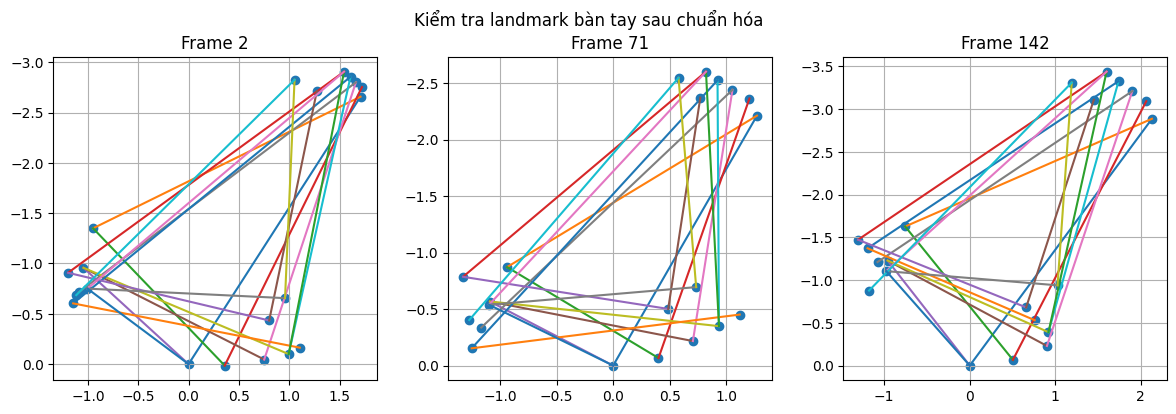

In [14]:
import numpy as np
import matplotlib.pyplot as plt

# Các cặp điểm nối theo cấu trúc bàn tay MediaPipe
connections = [
    (0,1),(1,2),(2,3),(3,4),
    (0,5),(5,6),(6,7),(7,8),
    (5,9),(9,10),(10,11),(11,12),
    (9,13),(13,14),(14,15),(15,16),
    (13,17),(17,18),(18,19),(19,20),
    (0,17)
]

# Chọn 3 frame có dữ liệu tay, phân bố trên clip
valid = np.where(tensor[:, 63] == 1)[0]
indices = valid[np.linspace(0, len(valid)-1, 3, dtype=int)]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, idx in zip(axes, indices):
    points = tensor[idx, :63].reshape(21, 3)

    # Vẽ các điểm và nối chúng thành hình bàn tay
    ax.scatter(points[:, 0], points[:, 1])

    for a, b in connections:
        ax.plot(
            [points[a, 0], points[b, 0]],
            [points[a, 1], points[b, 1]]
        )

    ax.set_title(f"Frame {idx}")
    ax.set_aspect("equal")
    ax.invert_yaxis()
    ax.grid(True)

plt.suptitle("Kiểm tra landmark bàn tay sau chuẩn hóa")
plt.tight_layout()
plt.show()

In [15]:
import numpy as np
import pyarrow as pa
import pyarrow.ipc as ipc
import tensorflow as tf
from pathlib import Path

path = Path(
    "/kaggle/working/daun_v3-train.arrow-00000-of-00100"
)

EDGES = [
    (0,1), (1,2), (2,3), (3,4),
    (0,5), (5,6), (6,7), (7,8),
    (5,9), (9,10), (10,11), (11,12),
    (9,13), (13,14), (14,15), (15,16),
    (13,17), (17,18), (18,19), (19,20),
    (0,17)
]

def bone_metrics(P):
    # P có dạng (21, 3)
    bone_lengths = np.array([
        np.linalg.norm(P[a, :2] - P[b, :2])
        for a, b in EDGES
    ])

    wrist_to_middle = np.linalg.norm(
        P[9, :2] - P[0, :2]
    )

    if wrist_to_middle < 1e-8:
        return np.nan, np.nan

    return (
        bone_lengths.mean(),
        bone_lengths.mean() / wrist_to_middle
    )

results = {"A": [], "B": []}

with pa.memory_map(str(path), "r") as source:
    reader = ipc.open_file(source)

    # Đọc một video, không đọc cả shard vào RAM
    raw = reader.get_batch(0).column("serialized")[0].as_py()

seq = tf.train.SequenceExample.FromString(raw)
fl = seq.feature_lists.feature_list

x_frames = fl["x_right_hand"].feature
y_frames = fl["y_right_hand"].feature
z_frames = fl["z_right_hand"].feature

used = 0

for t in range(len(x_frames)):
    arrays = []

    for frames in (x_frames, y_frames, z_frames):
        f = frames[t]

        if not f.HasField("float_list"):
            arrays = []
            break

        values = np.asarray(f.float_list.value, dtype=np.float32)

        if len(values) != 21:
            arrays = []
            break

        arrays.append(values)

    if not arrays:
        continue

    x, y, z = arrays

    # Cách A: 21 điểm, mỗi điểm có x, y, z
    A = np.stack([x, y, z], axis=1)

    # Cách B: ghép lại thành dãy 63 giá trị rồi chia thành 21 điểm
    B = np.concatenate([x, y, z]).reshape(21, 3)

    for name, P in [("A", A), ("B", B)]:
        mean_bone, ratio = bone_metrics(P)
        results[name].append((mean_bone, ratio))

    used += 1
    if used >= 10:
        break

print("Số frame đã so sánh:", used)

for name in ("A", "B"):
    values = np.asarray(results[name])

    print(f"\nCách {name}")
    print("Độ dài xương trung bình:",
          np.round(values[:, 0], 5))
    print("Tỷ lệ độ dài xương / cổ tay–gốc ngón giữa:",
          np.round(values[:, 1], 4))
    print("Tỷ lệ trung vị:",
          round(float(np.nanmedian(values[:, 1])), 4))

Số frame đã so sánh: 10

Cách A
Độ dài xương trung bình: [0.74243 0.71941 0.66031 0.65615 0.65806 0.66901 0.66744 0.65924 0.6577
 0.63772]
Tỷ lệ độ dài xương / cổ tay–gốc ngón giữa: [2.5805 2.7521 3.1066 3.0974 3.0745 3.0705 3.1208 3.0585 3.0326 2.906 ]
Tỷ lệ trung vị: 3.0645

Cách B
Độ dài xương trung bình: [0.22494 0.22142 0.2016  0.19931 0.2006  0.20435 0.2025  0.20004 0.19868
 0.19261]
Tỷ lệ độ dài xương / cổ tay–gốc ngón giữa: [0.24   0.258  0.2706 0.267  0.2652 0.2633 0.2624 0.2622 0.2643 0.2661]
Tỷ lệ trung vị: 0.2638


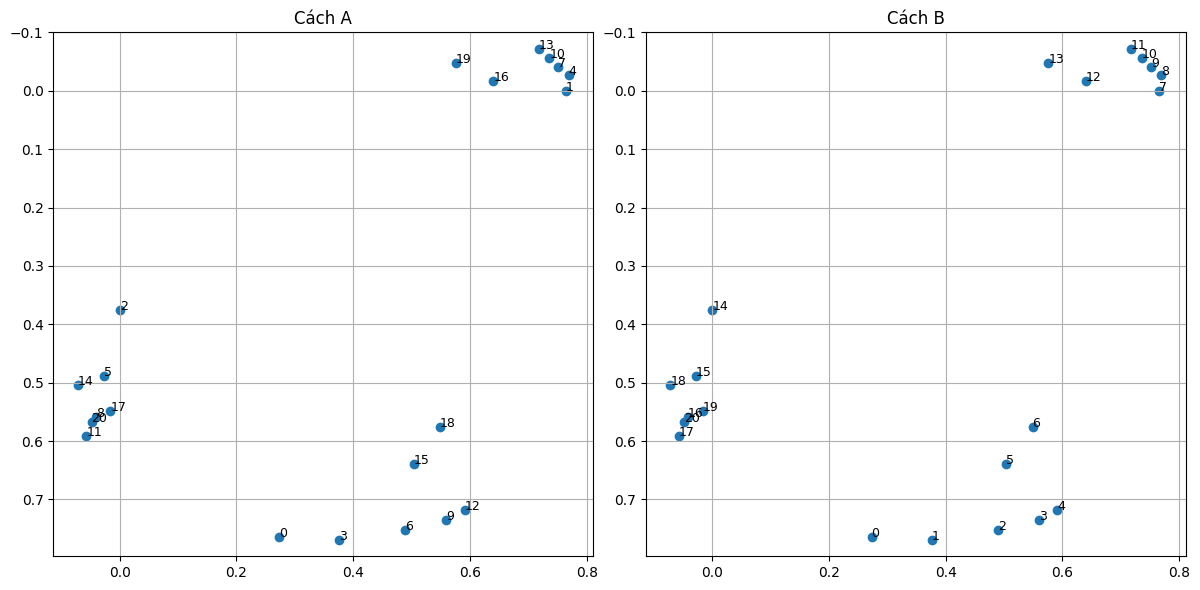

In [16]:
import numpy as np
import matplotlib.pyplot as plt

# Lấy frame đầu tiên có đủ 21 giá trị ở cả 3 trục
for t in range(len(x_frames)):
    values = []

    for frames in (x_frames, y_frames, z_frames):
        f = frames[t]
        if not f.HasField("float_list"):
            values = []
            break

        a = np.asarray(f.float_list.value, dtype=np.float32)
        if len(a) != 21:
            values = []
            break

        values.append(a)

    if values:
        x, y, z = values
        break
else:
    raise ValueError("Không tìm thấy frame có đủ tọa độ.")

A = np.stack([x, y, z], axis=1)
B = np.concatenate([x, y, z]).reshape(21, 3)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

for ax, P, title in zip(axes, [A, B], ["Cách A", "Cách B"]):
    ax.scatter(P[:, 0], P[:, 1])

    for i, (px, py, _) in enumerate(P):
        ax.annotate(str(i), (px, py), fontsize=9)

    ax.set_title(title)
    ax.set_aspect("equal", adjustable="datalim")
    ax.invert_yaxis()
    ax.grid(True)

plt.tight_layout()
plt.show()

In [17]:
import numpy as np
import pyarrow as pa
import pyarrow.ipc as ipc
import tensorflow as tf
from pathlib import Path

path = Path(
    "/kaggle/working/daun_v3-train.arrow-00000-of-00100"
)

# Đọc đúng một video đầu tiên trong shard
with pa.memory_map(str(path), "r") as source:
    reader = ipc.open_file(source)
    raw = reader.get_batch(0).column("serialized")[0].as_py()

seq = tf.train.SequenceExample.FromString(raw)
feature_lists = seq.feature_lists.feature_list

# 1. Liệt kê tất cả trường dữ liệu theo thời gian
print("=== ALL FEATURE LIST KEYS ===")
for name in sorted(feature_lists.keys()):
    frames = feature_lists[name].feature
    first_length = None

    if frames:
        frame = frames[0]
        if frame.HasField("float_list"):
            first_length = len(frame.float_list.value)
        elif frame.HasField("int64_list"):
            first_length = len(frame.int64_list.value)
        elif frame.HasField("bytes_list"):
            first_length = len(frame.bytes_list.value)

    print(f"{name}: {len(frames)} frames, first frame length={first_length}")

# Hàm đọc một trục tọa độ tại một frame
def read_axis(axis, t):
    frame = feature_lists[f"{axis}_right_hand"].feature[t]

    if not frame.HasField("float_list"):
        return np.array([], dtype=np.float32)

    return np.asarray(frame.float_list.value, dtype=np.float32)

# 2. Kiểm tra giả thuyết các dãy tọa độ bị lệch một vị trí
print("\n=== SHIFT HYPOTHESIS CHECK ===")

for t in [2, 71, 142]:
    x = read_axis("x", t)
    y = read_axis("y", t)
    z = read_axis("z", t)

    print(f"\nFrame {t}: lengths x/y/z = {len(x)}/{len(y)}/{len(z)}")

    if len(x) == len(y) == len(z) == 21:
        print("max |y[:-1] - x[1:]| =",
              float(np.max(np.abs(y[:-1] - x[1:]))))
        print("max |z[:-1] - y[1:]| =",
              float(np.max(np.abs(z[:-1] - y[1:]))))
    else:
        print("Frame này thiếu tọa độ; bỏ qua phép so sánh.")

=== ALL FEATURE LIST KEYS ===
presence_face: 159 frames, first frame length=478
presence_left_hand: 159 frames, first frame length=None
presence_pose: 159 frames, first frame length=25
presence_right_hand: 159 frames, first frame length=None
timestamp: 159 frames, first frame length=1
visibility_face: 159 frames, first frame length=478
visibility_left_hand: 159 frames, first frame length=None
visibility_pose: 159 frames, first frame length=25
visibility_right_hand: 159 frames, first frame length=None
x_face: 159 frames, first frame length=478
x_left_hand: 159 frames, first frame length=None
x_pose: 159 frames, first frame length=25
x_right_hand: 159 frames, first frame length=None
y_face: 159 frames, first frame length=478
y_left_hand: 159 frames, first frame length=None
y_pose: 159 frames, first frame length=25
y_right_hand: 159 frames, first frame length=None
z_face: 159 frames, first frame length=478
z_left_hand: 159 frames, first frame length=None
z_pose: 159 frames, first frame le

In [18]:
import requests

file_id = "1dhcrbZeb3-5IshIkzatVmNO3MOTVFjJW"
url = f"https://drive.google.com/uc?export=download&id={file_id}"

try:
    with requests.get(
        url, stream=True, allow_redirects=True, timeout=30
    ) as response:
        print("HTTP status:", response.status_code)
        print("Content-Type:", response.headers.get("Content-Type"))

        size = response.headers.get("Content-Length")
        if size and size.isdigit():
            print("Dung lượng (GiB):", round(int(size) / 1024**3, 2))
        else:
            print("Chưa xác định được dung lượng qua HTTP headers.")
except requests.RequestException as e:
    print("Không kiểm tra được:", repr(e))

HTTP status: 200
Content-Type: text/html; charset=utf-8
Dung lượng (GiB): 0.0


In [19]:
import shutil
import importlib.util

usage = shutil.disk_usage("/kaggle/working")

print("Dung lượng trống (GiB):", round(usage.free / 1024**3, 2))
print("Dung lượng tổng (GiB):", round(usage.total / 1024**3, 2))
print("Đã có gdown:", importlib.util.find_spec("gdown") is not None)

Dung lượng trống (GiB): 18.85
Dung lượng tổng (GiB): 19.52
Đã có gdown: True


In [20]:
!gdown --id 1dhcrbZeb3-5IshIkzatVmNO3MOTVFjJW \
  -O /kaggle/working/fsboard_proc_clean.zip

/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From (original): https://drive.google.com/uc?id=1dhcrbZeb3-5IshIkzatVmNO3MOTVFjJW
From (redirected): https://drive.google.com/uc?id=1dhcrbZeb3-5IshIkzatVmNO3MOTVFjJW&confirm=t&uuid=c2a869c2-987d-432d-a0fd-4cdc27fc5954
To: /kaggle/working/fsboard_proc_clean.zip
100%|██████████████████████████████████████| 6.36G/6.36G [01:22<00:00, 77.2MB/s]


In [21]:
import zipfile
from pathlib import Path

p = Path("/kaggle/working/fsboard_proc_clean.zip")

with zipfile.ZipFile(p) as z:
    files = z.infolist()
    print("Số tệp:", len(files))
    print("Tổng dung lượng giải nén (GiB):",
          round(sum(f.file_size for f in files) / 1024**3, 2))

    for f in files:
        print(f.filename, round(f.file_size / 1024**2, 1), "MiB")

Số tệp: 7
Tổng dung lượng giải nén (GiB): 6.79
fingerspelling_fsboard_proc_clean/ 0.0 MiB
fingerspelling_fsboard_proc_clean/fsboard_train_proc_clean.npz 5905.4 MiB
__MACOSX/fingerspelling_fsboard_proc_clean/._fsboard_train_proc_clean.npz 0.0 MiB
fingerspelling_fsboard_proc_clean/fsboard_validation_proc_clean.npz 489.2 MiB
__MACOSX/fingerspelling_fsboard_proc_clean/._fsboard_validation_proc_clean.npz 0.0 MiB
fingerspelling_fsboard_proc_clean/fsboard_test_proc_clean.npz 560.5 MiB
__MACOSX/fingerspelling_fsboard_proc_clean/._fsboard_test_proc_clean.npz 0.0 MiB


In [22]:
from pathlib import Path
import zipfile

archive = Path("/kaggle/working/fsboard_proc_clean.zip")
output = Path("/kaggle/working/fsboard_processed")

wanted = [
    "fingerspelling_fsboard_proc_clean/fsboard_train_proc_clean.npz",
    "fingerspelling_fsboard_proc_clean/fsboard_validation_proc_clean.npz",
]

output.mkdir(exist_ok=True)

with zipfile.ZipFile(archive, "r") as z:
    for name in wanted:
        target = output / Path(name).name

        if target.exists():
            print("Đã có, bỏ qua:", target.name)
            continue

        info = z.getinfo(name)
        print(f"Đang giải nén {target.name}: "
              f"{info.file_size / 1024**3:.2f} GiB")

        with z.open(name) as src, target.open("wb") as dst:
            while True:
                chunk = src.read(8 * 1024 * 1024)
                if not chunk:
                    break
                dst.write(chunk)

        print("Hoàn thành:", target.name)

print("\nCác tệp hiện có:")
for p in output.iterdir():
    print(p.name, f"{p.stat().st_size / 1024**3:.2f} GiB")

Đang giải nén fsboard_train_proc_clean.npz: 5.77 GiB
Hoàn thành: fsboard_train_proc_clean.npz
Đang giải nén fsboard_validation_proc_clean.npz: 0.48 GiB
Hoàn thành: fsboard_validation_proc_clean.npz

Các tệp hiện có:
fsboard_validation_proc_clean.npz 0.48 GiB
fsboard_train_proc_clean.npz 5.77 GiB


In [23]:
import zipfile
import numpy as np
from pathlib import Path

base = Path("/kaggle/working/fsboard_processed")

files = [
    base / "fsboard_train_proc_clean.npz",
    base / "fsboard_validation_proc_clean.npz",
]

for path in files:
    print(f"\n{'=' * 60}")
    print("FILE:", path.name)
    print("Tồn tại:", path.exists())

    if not path.exists():
        continue

    with zipfile.ZipFile(path, "r") as archive:
        for info in archive.infolist():
            if not info.filename.endswith(".npy"):
                continue

            with archive.open(info) as f:
                version = np.lib.format.read_magic(f)

                if version == (1, 0):
                    shape, fortran_order, dtype = (
                        np.lib.format.read_array_header_1_0(f)
                    )
                elif version in [(2, 0), (3, 0)]:
                    shape, fortran_order, dtype = (
                        np.lib.format.read_array_header_2_0(f)
                    )
                else:
                    print(info.filename, "Phiên bản NPY chưa hỗ trợ:", version)
                    continue

                print(f"\nMảng: {info.filename}")
                print("  Shape:", shape)
                print("  Dtype:", dtype)
                print("  Kích thước bên trong (MiB):",
                      round(info.file_size / 1024**2, 2))


FILE: fsboard_train_proc_clean.npz
Tồn tại: True

Mảng: vidnames.npy
  Shape: (126134,)
  Dtype: object
  Kích thước bên trong (MiB): 5.72

Mảng: right_hand_poses.npy
  Shape: (126134,)
  Dtype: object
  Kích thước bên trong (MiB): 4625.64

Mảng: left_hand_poses.npy
  Shape: (126134,)
  Dtype: object
  Kích thước bên trong (MiB): 997.42

Mảng: right_frame_indices.npy
  Shape: (126134,)
  Dtype: object
  Kích thước bên trong (MiB): 43.33

Mảng: left_frame_indices.npy
  Shape: (126134,)
  Dtype: object
  Kích thước bên trong (MiB): 14.24

Mảng: words.npy
  Shape: (126134,)
  Dtype: object
  Kích thước bên trong (MiB): 3.91

Mảng: signing_hand.npy
  Shape: (126134,)
  Dtype: object
  Kích thước bên trong (MiB): 0.24

Mảng: frame_label.npy
  Shape: (126134,)
  Dtype: object
  Kích thước bên trong (MiB): 180.79

Mảng: frame_label_clean.npy
  Shape: (24065,)
  Dtype: object
  Kích thước bên trong (MiB): 34.12

FILE: fsboard_validation_proc_clean.npz
Tồn tại: True

Mảng: vidnames.npy
  Shape

In [24]:
import numpy as np
from pathlib import Path

base = Path("/kaggle/working/fsboard_processed")

path = base / "fsboard_train_proc_clean.npz"

with np.load(path, allow_pickle=True) as data:
    print("Các mảng:", data.files)

    for key in [
        "vidnames",
        "words",
        "signing_hand",
        "right_frame_indices",
        "left_frame_indices",
    ]:
        arr = data[key]

        print(f"\n=== {key} ===")
        print("Shape:", arr.shape)
        print("Dtype:", arr.dtype)

        for i in range(min(3, len(arr))):
            print(f"Mẫu {i}:", repr(arr[i])[:500])

Các mảng: ['vidnames', 'right_hand_poses', 'left_hand_poses', 'right_frame_indices', 'left_frame_indices', 'words', 'signing_hand', 'frame_label', 'frame_label_clean']

=== vidnames ===
Shape: (126134,)
Dtype: object
Mẫu 0: '03ad_0_20220813_131811_103550_108200'
Mẫu 1: '03ad_0_20220813_131811_110000_113378'
Mẫu 2: '03ad_0_20220813_131811_128050_134100'

=== words ===
Shape: (126134,)
Dtype: object
Mẫu 0: '39 village oak court'
Mẫu 1: '2067 pso costa'
Mẫu 2: '7636 east 105th north'

=== signing_hand ===
Shape: (126134,)
Dtype: object
Mẫu 0: 1
Mẫu 1: 1
Mẫu 2: 1

=== right_frame_indices ===
Shape: (126134,)
Dtype: object
Mẫu 0: array([], dtype=int16)
Mẫu 1: array([], dtype=int16)
Mẫu 2: array([], dtype=int16)

=== left_frame_indices ===
Shape: (126134,)
Dtype: object
Mẫu 0: array([  0,   1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,
        13,  14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,
        26,  27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,
  

In [25]:
import numpy as np
from pathlib import Path

path = Path(
    "/kaggle/working/fsboard_processed/fsboard_train_proc_clean.npz"
)

with np.load(path, allow_pickle=True) as data:
    # Các thông tin nhỏ, dùng để xác định mẫu
    vidnames = data["vidnames"]
    words = data["words"]
    signing_hand = data["signing_hand"]
    left_indices = data["left_frame_indices"]
    right_indices = data["right_frame_indices"]

    # Chỉ đọc mảng tư thế tay trái
    left_poses = data["left_hand_poses"]

    i = 0

    entry = left_poses[i]
    print("Tên video:", vidnames[i])
    print("Nhãn đúng:", repr(words[i]))
    print("signing_hand:", signing_hand[i])
    print("Số frame tay trái:", len(left_indices[i]))
    print("Số frame tay phải:", len(right_indices[i]))

    print("\nKiểu dữ liệu của pose entry:", type(entry))

    # OpenFS lưu mỗi pose entry dưới dạng dictionary có khóa 0
    if isinstance(entry, dict) and 0 in entry:
        pose = np.asarray(entry[0])
    else:
        pose = np.asarray(entry)

    print("\n=== POSE ===")
    print("Shape:", pose.shape)
    print("Dtype:", pose.dtype)
    print("Có NaN/Inf:", not np.isfinite(pose).all())

    if pose.size:
        print("Min:", float(np.min(pose)))
        print("Max:", float(np.max(pose)))
        print("Shape của một frame:", pose[0].shape)

Tên video: 03ad_0_20220813_131811_103550_108200
Nhãn đúng: '39 village oak court'
signing_hand: 1
Số frame tay trái: 181
Số frame tay phải: 0

Kiểu dữ liệu của pose entry: <class 'dict'>

=== POSE ===
Shape: (181, 21, 3)
Dtype: float32
Có NaN/Inf: False
Min: -0.21627084910869598
Max: 2693.418212890625
Shape của một frame: (21, 3)


In [26]:
with np.load(path, allow_pickle=True) as data:
    pose = np.asarray(data["left_hand_poses"][0][0])

print("5 điểm đầu của frame 0:")
print(pose[0, :5, :])

print("\nMin/max theo từng trục:")
for axis, name in enumerate(["x", "y", "z"]):
    print(
        name,
        "min =", float(pose[:, :, axis].min()),
        "max =", float(pose[:, :, axis].max()),
        "mean =", float(pose[:, :, axis].mean())
    )

print("\nKhoảng cách cổ tay đến gốc ngón giữa:")
wrist = pose[:, 0, :]
middle_base = pose[:, 9, :]
distance = np.linalg.norm(middle_base - wrist, axis=1)

print("Min:", float(distance.min()))
print("Median:", float(np.median(distance)))
print("Max:", float(distance.max()))

5 điểm đầu của frame 0:
[[ 1.3847664e+03  2.4596287e+03 -8.9783168e-07]
 [ 1.2400287e+03  2.2902285e+03  2.3118092e-03]
 [ 1.1643064e+03  2.1043770e+03 -1.0731952e-02]
 [ 1.1291925e+03  1.9667733e+03 -3.6526095e-02]
 [ 1.1214202e+03  1.8413573e+03 -6.0828257e-02]]

Min/max theo từng trục:
x min = 714.7662963867188 max = 1902.6490478515625 mean = 1254.9334716796875
y min = 1264.8594970703125 max = 2693.418212890625 mean = 1976.5517578125
z min = -0.21627084910869598 max = 0.03232855349779129 mean = -0.08112543821334839

Khoảng cách cổ tay đến gốc ngón giữa:
Min: 350.5334167480469
Median: 532.892333984375
Max: 612.9771728515625


In [27]:
import numpy as np

path = "/kaggle/working/fsboard_processed/fsboard_train_proc_clean.npz"

with np.load(path, allow_pickle=True) as data:
    poses = data["left_hand_poses"]
    labels = data["words"]

    print("Số mẫu pose:", len(poses))
    print("Số nhãn:", len(labels))

    valid_count = 0
    empty_count = 0
    invalid_count = 0
    xy_ranges = []
    z_ranges = []

    # Kiểm tra tối đa 500 mẫu đầu để chạy nhanh
    for i in range(min(500, len(poses))):
        entry = poses[i]

        # Một số mẫu có thể không có pose tay trái
        try:
            pose = np.asarray(entry[0], dtype=np.float32)
        except (KeyError, IndexError, TypeError, ValueError):
            empty_count += 1
            continue

        if pose.size == 0:
            empty_count += 1
            continue

        if pose.ndim != 3 or pose.shape[1:] != (21, 3):
            invalid_count += 1
            continue

        if not np.isfinite(pose).all():
            invalid_count += 1
            continue

        valid_count += 1
        xy_ranges.append([
            pose[:, :, 0].min(),
            pose[:, :, 0].max(),
            pose[:, :, 1].min(),
            pose[:, :, 1].max()
        ])
        z_ranges.append([
            pose[:, :, 2].min(),
            pose[:, :, 2].max()
        ])

    print("\nTrong 500 mẫu đầu:")
    print("Pose hợp lệ:", valid_count)
    print("Pose rỗng/không đọc được:", empty_count)
    print("Pose sai shape hoặc NaN/Inf:", invalid_count)

    if xy_ranges:
        xy_ranges = np.asarray(xy_ranges)
        z_ranges = np.asarray(z_ranges)

        print("\nTrung vị các giá trị theo video:")
        print("x min:", np.median(xy_ranges[:, 0]))
        print("x max:", np.median(xy_ranges[:, 1]))
        print("y min:", np.median(xy_ranges[:, 2]))
        print("y max:", np.median(xy_ranges[:, 3]))
        print("z min:", np.median(z_ranges[:, 0]))
        print("z max:", np.median(z_ranges[:, 1]))

Số mẫu pose: 126134
Số nhãn: 126134

Trong 500 mẫu đầu:
Pose hợp lệ: 500
Pose rỗng/không đọc được: 0
Pose sai shape hoặc NaN/Inf: 0

Trung vị các giá trị theo video:
x min: 569.75
x max: 1836.3726
y min: 1317.0386
y max: 3385.1567
z min: -0.30133906
z max: 0.028826475


In [28]:
import numpy as np

path = "/kaggle/working/fsboard_processed/fsboard_train_proc_clean.npz"

with np.load(path, allow_pickle=True) as data:
    pose = np.asarray(data["left_hand_poses"][0][0], dtype=np.float32)

# pose: (frames, 21, 3)
# Landmark 0: cổ tay; landmark 9: gốc ngón giữa
wrist = pose[:, 0:1, :]
scale = np.linalg.norm(pose[:, 9, :] - pose[:, 0, :], axis=1)

# Tránh chia cho 0 hoặc giá trị quá nhỏ
valid = scale > 1e-6
print("Tổng frame:", len(scale))
print("Frame có scale hợp lệ:", int(valid.sum()))
print("Scale min / median / max:",
      float(scale.min()), float(np.median(scale)), float(scale.max()))

normalized = (pose - wrist) / np.maximum(scale[:, None, None], 1e-6)

print("\nShape sau chuẩn hóa:", normalized.shape)
print("Có NaN/Inf:", not np.isfinite(normalized).all())
print("Min/max sau chuẩn hóa:",
      float(normalized.min()), float(normalized.max()))
print("Cổ tay ở frame đầu:", normalized[0, 0, :])

Tổng frame: 181
Frame có scale hợp lệ: 181
Scale min / median / max: 350.5334167480469 532.892333984375 612.9771728515625

Shape sau chuẩn hóa: (181, 21, 3)
Có NaN/Inf: False
Min/max sau chuẩn hóa: -2.178966760635376 0.7842712998390198
Cổ tay ở frame đầu: [0. 0. 0.]


In [29]:
import numpy as np

path = "/kaggle/working/fsboard_processed/fsboard_train_proc_clean.npz"

with np.load(path, allow_pickle=True) as data:
    poses = data["left_hand_poses"]
    labels = data["words"]

    lengths = []
    label_lengths = []
    empty_pose = 0
    empty_label = 0

    for i in range(len(poses)):
        try:
            pose = np.asarray(poses[i][0])
        except (KeyError, IndexError, TypeError, ValueError):
            empty_pose += 1
            continue

        if pose.ndim != 3 or pose.shape[1:] != (21, 3):
            empty_pose += 1
            continue

        lengths.append(len(pose))

        label = labels[i]
        if isinstance(label, bytes):
            label = label.decode("utf-8")
        label = str(label)

        label_lengths.append(len(label))
        if not label.strip():
            empty_label += 1

    lengths = np.asarray(lengths)
    label_lengths = np.asarray(label_lengths)

    for name, values in [
        ("Số frame/video", lengths),
        ("Số ký tự/nhãn", label_lengths),
    ]:
        print(f"\n{name}:")
        print("Min:", int(values.min()))
        print("P50:", int(np.percentile(values, 50)))
        print("P90:", int(np.percentile(values, 90)))
        print("P95:", int(np.percentile(values, 95)))
        print("P99:", int(np.percentile(values, 99)))
        print("Max:", int(values.max()))

    print("\nSố pose không hợp lệ:", empty_pose)
    print("Số nhãn rỗng:", empty_label)


Số frame/video:
Min: 1
P50: 99
P90: 242
P95: 293
P99: 391
Max: 747

Số ký tự/nhãn:
Min: 3
P50: 22
P90: 32
P95: 34
P99: 39
Max: 43

Số pose không hợp lệ: 86799
Số nhãn rỗng: 0


In [30]:
import numpy as np
from collections import Counter

path = "/kaggle/working/fsboard_processed/fsboard_train_proc_clean.npz"

with np.load(path, allow_pickle=True) as data:
    left = data["left_hand_poses"]
    right = data["right_hand_poses"]
    signing_hand = data["signing_hand"]

    print("Phân bố signing_hand:")
    print(Counter(str(x) for x in signing_hand))

    print("\nCấu trúc 5 mẫu đầu:")
    for i in range(5):
        print(f"\nMẫu {i}, signing_hand={signing_hand[i]}")

        for name, arr in [
            ("left", left),
            ("right", right),
        ]:
            entry = arr[i]
            print(f"  {name}: type={type(entry).__name__}")

            if isinstance(entry, dict):
                print("    keys:", list(entry.keys())[:5])

            try:
                pose = np.asarray(entry[0], dtype=np.float32)
                print("    shape:", pose.shape)
            except Exception as e:
                print("    Không đọc được entry[0]:", repr(e))

Phân bố signing_hand:
Counter({'0': 106144, '1': 19903, 'None': 87})

Cấu trúc 5 mẫu đầu:

Mẫu 0, signing_hand=1
  left: type=dict
    keys: [0]
    shape: (181, 21, 3)
  right: type=dict
    keys: [0]
    shape: (0,)

Mẫu 1, signing_hand=1
  left: type=dict
    keys: [0]
    shape: (121, 21, 3)
  right: type=dict
    keys: [0]
    shape: (0,)

Mẫu 2, signing_hand=1
  left: type=dict
    keys: [0]
    shape: (210, 21, 3)
  right: type=dict
    keys: [0]
    shape: (0,)

Mẫu 3, signing_hand=1
  left: type=dict
    keys: [0]
    shape: (181, 21, 3)
  right: type=dict
    keys: [0]
    shape: (0,)

Mẫu 4, signing_hand=1
  left: type=dict
    keys: [0]
    shape: (151, 21, 3)
  right: type=dict
    keys: [0]
    shape: (0,)


In [31]:
import numpy as np

path = "/kaggle/working/fsboard_processed/fsboard_train_proc_clean.npz"

with np.load(path, allow_pickle=True) as data:
    left = data["left_hand_poses"]
    right = data["right_hand_poses"]
    signing_hand = data["signing_hand"]

    found = 0

    for i, hand in enumerate(signing_hand):
        if hand is None:
            continue

        try:
            if int(hand) != 0:
                continue
        except (TypeError, ValueError):
            continue

        print(f"\nMẫu {i}, signing_hand={hand}")

        for name, arr in [("left", left), ("right", right)]:
            try:
                pose = np.asarray(arr[i][0], dtype=np.float32)
                print(f"  {name}: shape={pose.shape}")
            except Exception as e:
                print(f"  {name}: không đọc được ({type(e).__name__})")

        found += 1
        if found == 3:
            break


Mẫu 677, signing_hand=0
  left: shape=(0,)
  right: shape=(205, 21, 3)

Mẫu 678, signing_hand=0
  left: shape=(0,)
  right: shape=(148, 21, 3)

Mẫu 679, signing_hand=0
  left: shape=(0,)
  right: shape=(243, 21, 3)


In [32]:
import numpy as np
from collections import Counter

path = "/kaggle/working/fsboard_processed/fsboard_train_proc_clean.npz"

with np.load(path, allow_pickle=True) as data:
    left = data["left_hand_poses"]
    right = data["right_hand_poses"]
    hands = data["signing_hand"]
    labels = data["words"]

    lengths = []
    label_lengths = []
    hand_counts = Counter()
    empty_pose = 0
    invalid_pose = 0
    missing_hand = 0

    for i, hand in enumerate(hands):
        # Chọn đúng tay theo metadata
        try:
            h = int(hand)
        except (TypeError, ValueError):
            missing_hand += 1
            continue

        if h not in (0, 1):
            missing_hand += 1
            continue

        hand_counts[h] += 1
        selected = right[i] if h == 0 else left[i]

        try:
            pose = np.asarray(selected[0], dtype=np.float32)
        except (KeyError, IndexError, TypeError, ValueError):
            empty_pose += 1
            continue

        if pose.size == 0:
            empty_pose += 1
            continue

        if (
            pose.ndim != 3
            or pose.shape[1:] != (21, 3)
            or not np.isfinite(pose).all()
        ):
            invalid_pose += 1
            continue

        label = labels[i]
        if isinstance(label, bytes):
            label = label.decode("utf-8")
        label = str(label)

        lengths.append(len(pose))
        label_lengths.append(len(label))

    lengths = np.asarray(lengths)
    label_lengths = np.asarray(label_lengths)

    print("Phân bố signing_hand:", dict(hand_counts))
    print("Mẫu không có signing_hand hợp lệ:", missing_hand)
    print("Pose rỗng:", empty_pose)
    print("Pose sai shape hoặc chứa NaN/Inf:", invalid_pose)
    print("Tổng video có pose hợp lệ:", len(lengths))

    if len(lengths):
        for name, values in [
            ("Số frame/video", lengths),
            ("Số ký tự/nhãn", label_lengths),
        ]:
            print(f"\n{name}:")
            for p in [0, 50, 90, 95, 99, 100]:
                print(f"P{p}: {np.percentile(values, p):.0f}")

Phân bố signing_hand: {1: 19903, 0: 106144}
Mẫu không có signing_hand hợp lệ: 87
Pose rỗng: 0
Pose sai shape hoặc chứa NaN/Inf: 0
Tổng video có pose hợp lệ: 126047

Số frame/video:
P0: 11
P50: 171
P90: 271
P95: 312
P99: 404
P100: 770

Số ký tự/nhãn:
P0: 1
P50: 23
P90: 32
P95: 35
P99: 39
P100: 43


In [33]:
import numpy as np

path = "/kaggle/working/fsboard_processed/fsboard_train_proc_clean.npz"

def to_text(value):
    if isinstance(value, bytes):
        return value.decode("utf-8")
    if isinstance(value, np.str_):
        return str(value)
    return str(value)

def min_ctc_frames(text):
    # Mỗi ký tự cần ít nhất một frame.
    # Hai ký tự giống nhau liên tiếp cần thêm một frame.
    repeated_neighbors = sum(
        text[i] == text[i - 1]
        for i in range(1, len(text))
    )
    return len(text) + repeated_neighbors

valid_count = 0
impossible_count = 0
examples = []

with np.load(path, allow_pickle=True) as data:
    left = data["left_hand_poses"]
    right = data["right_hand_poses"]
    hands = data["signing_hand"]
    labels = data["words"]

    for i, hand in enumerate(hands):
        try:
            h = int(hand)
        except (TypeError, ValueError):
            continue

        if h not in (0, 1):
            continue

        selected = right[i] if h == 0 else left[i]

        try:
            pose = np.asarray(selected[0], dtype=np.float32)
        except (KeyError, IndexError, TypeError, ValueError):
            continue

        if (
            pose.ndim != 3
            or pose.shape[1:] != (21, 3)
            or not np.isfinite(pose).all()
            or len(pose) == 0
        ):
            continue

        label = to_text(labels[i])
        required = min_ctc_frames(label)
        valid_count += 1

        if len(pose) < required:
            impossible_count += 1
            if len(examples) < 10:
                examples.append(
                    (i, len(pose), repr(label), len(label), required)
                )

print("Số mẫu pose hợp lệ đã kiểm tra:", valid_count)
print("Số mẫu không đủ frame cho CTC:", impossible_count)
print(
    "Tỷ lệ không đủ frame:",
    f"{100 * impossible_count / max(valid_count, 1):.4f}%"
)

print("\nMột số mẫu không đủ frame (nếu có):")
for item in examples:
    print(
        f"index={item[0]}, frames={item[1]}, label={item[2]}, "
        f"label_len={item[3]}, min_ctc_frames={item[4]}"
    )

Số mẫu pose hợp lệ đã kiểm tra: 126047
Số mẫu không đủ frame cho CTC: 2
Tỷ lệ không đủ frame: 0.0016%

Một số mẫu không đủ frame (nếu có):
index=77026, frames=20, label='take a coffee break', label_len=19, min_ctc_frames=21
index=91208, frames=29, label='longer than a football field', label_len=28, min_ctc_frames=30


In [34]:
# ============================================================
# DAY 3 — FSboard preprocessing + BiGRU-CTC smoke test
# ============================================================

import os
import random
from collections import Counter

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import (
    pack_padded_sequence,
    pad_packed_sequence,
)

# -------------------------
# 0. Configuration
# -------------------------
TRAIN_PATH = "/kaggle/working/fsboard_processed/fsboard_train_proc_clean.npz"
VAL_PATH = "/kaggle/working/fsboard_processed/fsboard_validation_proc_clean.npz"

SEED = 42
BATCH_SIZE = 8
SMOKE_STEPS = 8
HIDDEN_SIZE = 128
NUM_LAYERS = 2

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


# -------------------------
# 1. Data loading and filtering
# -------------------------
def text_value(value):
    if isinstance(value, (bytes, np.bytes_)):
        return value.decode("utf-8")
    return str(value)


def minimum_ctc_frames(text):
    # CTC cần thêm frame cho mỗi cặp ký tự giống nhau liên tiếp.
    repeated = sum(
        text[i] == text[i - 1]
        for i in range(1, len(text))
    )
    return len(text) + repeated


def load_split(path, split_name):
    if not os.path.exists(path):
        raise FileNotFoundError(f"Không tìm thấy file: {path}")

    examples = []
    stats = Counter()

    print(f"\nĐang đọc {split_name}: {path}")

    with np.load(path, allow_pickle=True) as data:
        left = data["left_hand_poses"]
        right = data["right_hand_poses"]
        hands = data["signing_hand"]
        labels = data["words"]

        stats["total"] = len(labels)

        for i in range(len(labels)):
            if (i + 1) % 25000 == 0:
                print(f"  Đã kiểm tra {i + 1:,}/{len(labels):,} mẫu")

            # signing_hand = 0: tay phải
            # signing_hand = 1: tay trái
            try:
                hand = int(hands[i])
            except (TypeError, ValueError):
                stats["missing_hand"] += 1
                continue

            if hand not in (0, 1):
                stats["missing_hand"] += 1
                continue

            entry = right[i] if hand == 0 else left[i]

            try:
                pose = np.asarray(entry[0], dtype=np.float32)
            except (KeyError, IndexError, TypeError, ValueError):
                stats["unreadable_pose"] += 1
                continue

            if pose.size == 0:
                stats["empty_pose"] += 1
                continue

            if (
                pose.ndim != 3
                or pose.shape[1:] != (21, 3)
            ):
                stats["bad_shape"] += 1
                continue

            if not np.isfinite(pose).all():
                stats["bad_values"] += 1
                continue

            label = text_value(labels[i])

            if not label.strip():
                stats["empty_label"] += 1
                continue

            if len(pose) < minimum_ctc_frames(label):
                stats["too_short_for_ctc"] += 1
                continue

            # Giữ lại array gốc, chưa tạo bản sao của cả dataset.
            examples.append((pose, label))
            stats["kept"] += 1

    print(f"\n{split_name} summary:")
    for key, value in stats.items():
        print(f"  {key}: {value}")

    return examples, stats


train_examples, train_stats = load_split(TRAIN_PATH, "TRAIN")

if len(train_examples) == 0:
    raise RuntimeError("Không còn mẫu train hợp lệ.")

# -------------------------
# 2. Character vocabulary
# -------------------------
characters = sorted(set(
    char
    for _, label in train_examples
    for char in label
))

# CTC blank dùng index 0; các ký tự bắt đầu từ index 1.
char_to_idx = {char: i + 1 for i, char in enumerate(characters)}
idx_to_char = {i + 1: char for i, char in enumerate(characters)}

BLANK_IDX = 0
NUM_CLASSES = len(characters) + 1

print("\nVocabulary:")
print("  Số ký tự:", len(characters))
print("  Số output classes (bao gồm CTC blank):", NUM_CLASSES)
print("  Ký tự:", repr("".join(characters)))


# -------------------------
# 3. Load validation + check vocabulary
# -------------------------
val_examples, val_stats = load_split(VAL_PATH, "VALIDATION")

known_chars = set(char_to_idx)
val_unknown = [
    (pose, label)
    for pose, label in val_examples
    if any(char not in known_chars for char in label)
]

if val_unknown:
    print(
        "\nCẢNH BÁO:",
        len(val_unknown),
        "mẫu validation có ký tự không xuất hiện trong train."
    )
    val_examples = [
        (pose, label)
        for pose, label in val_examples
        if all(char in known_chars for char in label)
    ]
else:
    print("\nTất cả ký tự trong validation đều có trong vocabulary train.")

print("Số mẫu train dùng được:", len(train_examples))
print("Số mẫu validation dùng được:", len(val_examples))

if len(val_examples) == 0:
    raise RuntimeError("Không còn mẫu validation hợp lệ.")


# -------------------------
# 4. Normalization
# -------------------------
def normalize_pose(pose):
    """
    Input:  (T, 21, 3)
    Output: (T, 63)

    - Đưa cổ tay (landmark 0) về gốc tọa độ ở mỗi frame.
    - Chia cho khoảng cách từ cổ tay tới landmark 9.
    - Bảo vệ trước scale quá nhỏ.
    """
    pose = np.asarray(pose, dtype=np.float32)

    wrist = pose[:, 0:1, :]
    scale = np.linalg.norm(
        pose[:, 9, :] - pose[:, 0, :],
        axis=1
    )

    # Dataset đang dùng tọa độ x/y cỡ pixel.
    # Tránh chia cho một scale gần 0.
    scale = np.maximum(scale, 1.0)

    normalized = (pose - wrist) / scale[:, None, None]

    # Giới hạn các outlier cực đoan cho smoke test ổn định.
    normalized = np.clip(normalized, -5.0, 5.0)

    return np.ascontiguousarray(
        normalized.reshape(len(pose), 21 * 3),
        dtype=np.float32
    )


class PoseTextDataset(Dataset):
    def __init__(self, examples):
        self.examples = examples

    def __len__(self):
        return len(self.examples)

    def __getitem__(self, index):
        pose, label = self.examples[index]

        features = normalize_pose(pose)
        target = np.asarray(
            [char_to_idx[char] for char in label],
            dtype=np.int64
        )

        return (
            torch.from_numpy(features),
            torch.from_numpy(target),
            label,
        )


def collate_batch(batch):
    features, targets, texts = zip(*batch)

    batch_size = len(features)
    lengths = torch.tensor(
        [x.shape[0] for x in features],
        dtype=torch.long
    )

    max_frames = int(lengths.max())

    padded = torch.zeros(
        batch_size, max_frames, 63,
        dtype=torch.float32
    )

    for i, x in enumerate(features):
        padded[i, :x.shape[0]] = x

    target_lengths = torch.tensor(
        [len(y) for y in targets],
        dtype=torch.long
    )
    concatenated_targets = torch.cat(targets)

    return (
        padded,
        concatenated_targets,
        lengths,
        target_lengths,
        list(texts),
    )


train_dataset = PoseTextDataset(train_examples)
val_dataset = PoseTextDataset(val_examples)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_batch,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
    generator=torch.Generator().manual_seed(SEED),
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_batch,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
)

# Kiểm tra một batch trước khi khởi tạo model.
x_check, y_check, len_check, target_len_check, text_check = next(iter(train_loader))

print("\nBatch sanity check:")
print("  X:", tuple(x_check.shape), "(B, T, 63)")
print("  Targets:", tuple(y_check.shape), "(chuỗi target đã nối)")
print("  Input lengths:", len_check.tolist())
print("  Target lengths:", target_len_check.tolist())
print("  Features finite:", bool(torch.isfinite(x_check).all()))
print(
    "  Max target length <= input length:",
    all(
        int(t) <= int(n)
        for t, n in zip(target_len_check, len_check)
    )
)

del x_check, y_check, len_check, target_len_check, text_check


# -------------------------
# 5. BiGRU + CTC model
# -------------------------
class BiGRUCTC(nn.Module):
    def __init__(
        self,
        input_dim,
        hidden_size,
        num_layers,
        num_classes,
    ):
        super().__init__()

        self.gru = nn.GRU(
            input_size=input_dim,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True,
            dropout=0.2 if num_layers > 1 else 0.0,
        )

        self.dropout = nn.Dropout(0.2)
        self.classifier = nn.Linear(
            hidden_size * 2,
            num_classes
        )

    def forward(self, x, lengths):
        # lengths giữ trên CPU để pack_padded_sequence dùng trực tiếp.
        packed = pack_padded_sequence(
            x,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False,
        )

        packed_output, _ = self.gru(packed)

        output, _ = pad_packed_sequence(
            packed_output,
            batch_first=True,
            total_length=x.shape[1],
        )

        logits = self.classifier(self.dropout(output))

        # CTC yêu cầu shape (T, B, C).
        return logits.transpose(0, 1).contiguous()


model = BiGRUCTC(
    input_dim=63,
    hidden_size=HIDDEN_SIZE,
    num_layers=NUM_LAYERS,
    num_classes=NUM_CLASSES,
).to(device)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-4,
)

ctc_loss_fn = nn.CTCLoss(
    blank=BLANK_IDX,
    zero_infinity=True,
)

print("\nModel:")
print("  Parameters:", f"{sum(p.numel() for p in model.parameters()):,}")
print("  Hidden size:", HIDDEN_SIZE)
print("  BiGRU layers:", NUM_LAYERS)


# -------------------------
# 6. Train a few minibatches
# -------------------------
model.train()
train_losses = []

print(f"\nBắt đầu smoke training: {SMOKE_STEPS} minibatches")

for step, batch in enumerate(train_loader, start=1):
    x, targets, input_lengths, target_lengths, texts = batch

    x = x.to(device, non_blocking=True)
    targets = targets.to(device, non_blocking=True)

    optimizer.zero_grad(set_to_none=True)

    logits = model(x, input_lengths)
    log_probs = F.log_softmax(logits, dim=-1).contiguous()

    loss = ctc_loss_fn(
        log_probs,
        targets,
        input_lengths,   # CPU lengths
        target_lengths,  # CPU lengths
    )

    if not torch.isfinite(loss).item():
        raise RuntimeError(
            f"CTC loss không hữu hạn tại bước {step}: {loss.item()}"
        )

    loss.backward()

    grad_norm = torch.nn.utils.clip_grad_norm_(
        model.parameters(),
        max_norm=5.0,
    )

    optimizer.step()

    loss_value = float(loss.detach().cpu())
    grad_value = float(grad_norm.detach().cpu())
    train_losses.append(loss_value)

    print(
        f"Step {step:02d}/{SMOKE_STEPS} | "
        f"loss={loss_value:.4f} | "
        f"grad_norm={grad_value:.4f} | "
        f"batch_max_T={x.shape[1]}"
    )

    if step >= SMOKE_STEPS:
        break


# -------------------------
# 7. Validation forward + greedy decode
# -------------------------
def greedy_decode(log_probs, input_lengths):
    # log_probs: (T, B, C)
    predicted_ids = log_probs.argmax(dim=-1)
    decoded = []

    for b in range(predicted_ids.shape[1]):
        length = int(input_lengths[b])
        sequence = predicted_ids[:length, b].tolist()

        output_chars = []
        previous = BLANK_IDX

        for idx in sequence:
            # CTC: bỏ blank và gộp các ký tự lặp liền nhau.
            if idx != BLANK_IDX and idx != previous:
                output_chars.append(idx_to_char[idx])
            previous = idx

        decoded.append("".join(output_chars))

    return decoded


model.eval()

with torch.no_grad():
    val_batch = next(iter(val_loader))
    x, targets, input_lengths, target_lengths, texts = val_batch

    x = x.to(device, non_blocking=True)
    targets = targets.to(device, non_blocking=True)

    logits = model(x, input_lengths)
    log_probs = F.log_softmax(logits, dim=-1).contiguous()

    val_loss = ctc_loss_fn(
        log_probs,
        targets,
        input_lengths,
        target_lengths,
    )

    predictions = greedy_decode(log_probs, input_lengths)

print("\nValidation smoke test:")
print("  Val loss:", float(val_loss.cpu()))
print("  Output shape (T, B, C):", tuple(log_probs.shape))
print("\nVí dụ đầu ra:")
print("  Ground truth:", repr(texts[0]))
print("  Prediction  :", repr(predictions[0]))

if not torch.isfinite(val_loss).item():
    raise RuntimeError("Validation loss không hữu hạn.")

print("\nSMOKE TEST PASSED")
print("Đã chạy preprocessing -> DataLoader -> BiGRU -> CTC -> validation.")
print("Lưu ý: đây mới là vài minibatch kiểm tra pipeline, chưa phải mô hình đã hội tụ.")

Device: cuda
GPU: Tesla T4

Đang đọc TRAIN: /kaggle/working/fsboard_processed/fsboard_train_proc_clean.npz
  Đã kiểm tra 25,000/126,134 mẫu
  Đã kiểm tra 50,000/126,134 mẫu
  Đã kiểm tra 75,000/126,134 mẫu
  Đã kiểm tra 100,000/126,134 mẫu
  Đã kiểm tra 125,000/126,134 mẫu

TRAIN summary:
  total: 126134
  kept: 126045
  missing_hand: 87
  too_short_for_ctc: 2

Vocabulary:
  Số ký tự: 59
  Số output classes (bao gồm CTC blank): 60
  Ký tự: " !#$%&'()*+,-./0123456789:;=?@[_abcdefghijklmnopqrstuvwxyz~"

Đang đọc VALIDATION: /kaggle/working/fsboard_processed/fsboard_validation_proc_clean.npz

VALIDATION summary:
  total: 12015
  kept: 12005
  missing_hand: 10

Tất cả ký tự trong validation đều có trong vocabulary train.
Số mẫu train dùng được: 126045
Số mẫu validation dùng được: 12005

Batch sanity check:
  X: (8, 276, 63) (B, T, 63)
  Targets: (205,) (chuỗi target đã nối)
  Input lengths: [84, 148, 276, 164, 207, 236, 151, 78]
  Target lengths: [21, 30, 43, 18, 30, 21, 26, 16]
  Features

In [35]:
import os
import numpy as np
import torch
import torch.nn.functional as F

from torch.utils.data import DataLoader, Subset

# =========================
# 1. Cấu hình thử nghiệm
# =========================
SEED = 42
BATCH_SIZE = 16
N_TRAIN = 6400
N_VAL = 512
MAX_STEPS = 400

torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Chọn ngẫu nhiên tập con nhưng có thể tái lập
rng = np.random.default_rng(SEED)

train_ids = rng.choice(
    len(train_dataset),
    size=min(N_TRAIN, len(train_dataset)),
    replace=False,
).tolist()

val_ids = rng.choice(
    len(val_dataset),
    size=min(N_VAL, len(val_dataset)),
    replace=False,
).tolist()

train_subset = Subset(train_dataset, train_ids)
val_subset = Subset(val_dataset, val_ids)

train_loader_quick = DataLoader(
    train_subset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_batch,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
    generator=torch.Generator().manual_seed(SEED),
)

val_loader_quick = DataLoader(
    val_subset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_batch,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
)

print("Device:", device)
print("Train subset:", len(train_subset))
print("Validation subset:", len(val_subset))
print("Train batches:", len(train_loader_quick))


# =========================
# 2. Khởi tạo model mới
# =========================
model = BiGRUCTC(
    input_dim=63,
    hidden_size=128,
    num_layers=2,
    num_classes=NUM_CLASSES,
).to(device)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-4,
)

ctc_loss_fn = torch.nn.CTCLoss(
    blank=BLANK_IDX,
    zero_infinity=True,
)

# =========================
# 3. Train tối đa 400 batch
# =========================
model.train()
train_losses = []

for step, batch in enumerate(train_loader_quick, start=1):
    x, targets, input_lengths, target_lengths, texts = batch

    x = x.to(device, non_blocking=True)
    targets = targets.to(device, non_blocking=True)

    optimizer.zero_grad(set_to_none=True)

    logits = model(x, input_lengths)
    log_probs = F.log_softmax(logits, dim=-1)

    loss = ctc_loss_fn(
        log_probs,
        targets,
        input_lengths,
        target_lengths,
    )

    if not torch.isfinite(loss).item():
        raise RuntimeError(f"Loss không hữu hạn tại step {step}")

    loss.backward()

    grad_norm = torch.nn.utils.clip_grad_norm_(
        model.parameters(), max_norm=5.0
    )
    optimizer.step()

    train_losses.append(float(loss.detach().cpu()))

    if step == 1 or step % 50 == 0:
        recent = train_losses[-50:]
        print(
            f"Step {step:03d}/{min(MAX_STEPS, len(train_loader_quick))} | "
            f"loss={train_losses[-1]:.4f} | "
            f"mean_recent={np.mean(recent):.4f} | "
            f"grad_norm={float(grad_norm):.4f}"
        )

    if step >= MAX_STEPS:
        break

print("Số minibatch đã train:", len(train_losses))


# =========================
# 4. Greedy decoding + CER
# =========================
def greedy_decode_batch(log_probs, input_lengths):
    # log_probs: (T, B, C)
    ids = log_probs.argmax(dim=-1)
    predictions = []

    for b in range(ids.shape[1]):
        sequence = ids[:int(input_lengths[b]), b].tolist()

        chars = []
        previous = BLANK_IDX

        for token in sequence:
            # CTC: gộp token lặp liền nhau rồi loại blank
            if token != BLANK_IDX and token != previous:
                chars.append(idx_to_char[token])
            previous = token

        predictions.append("".join(chars))

    return predictions


def edit_distance(a, b):
    # Levenshtein distance, dùng để tính CER
    previous = list(range(len(b) + 1))

    for i, ca in enumerate(a, start=1):
        current = [i]
        for j, cb in enumerate(b, start=1):
            current.append(min(
                current[-1] + 1,          # insertion
                previous[j] + 1,           # deletion
                previous[j - 1] + (ca != cb),  # substitution
            ))
        previous = current

    return previous[-1]


model.eval()
val_losses = []
total_edits = 0
total_chars = 0
examples_to_show = []

with torch.no_grad():
    for batch in val_loader_quick:
        x, targets, input_lengths, target_lengths, texts = batch
        x = x.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)

        logits = model(x, input_lengths)
        log_probs = F.log_softmax(logits, dim=-1)

        loss = ctc_loss_fn(
            log_probs,
            targets,
            input_lengths,
            target_lengths,
        )
        val_losses.append(float(loss.cpu()))

        predictions = greedy_decode_batch(log_probs, input_lengths)

        for truth, pred in zip(texts, predictions):
            total_edits += edit_distance(truth, pred)
            total_chars += len(truth)

            if len(examples_to_show) < 10:
                examples_to_show.append((truth, pred))

val_cer = total_edits / max(total_chars, 1)

print("\n========== QUICK EXPERIMENT RESULTS ==========")
print("Mean train loss (last 50 batches):",
      round(float(np.mean(train_losses[-50:])), 4))
print("Mean validation CTC loss:",
      round(float(np.mean(val_losses)), 4))
print("Validation CER:",
      f"{100 * val_cer:.2f}%")

print("\nPrediction examples:")
for truth, pred in examples_to_show:
    print("TRUE:", repr(truth))
    print("PRED:", repr(pred))
    print()

# =========================
# 5. Lưu checkpoint
# =========================
checkpoint_path = "/kaggle/working/bigru_ctc_quick.pt"

torch.save({
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "char_to_idx": char_to_idx,
    "idx_to_char": idx_to_char,
    "blank_idx": BLANK_IDX,
    "input_dim": 63,
    "hidden_size": 128,
    "num_layers": 2,
    "num_classes": NUM_CLASSES,
    "train_samples": len(train_subset),
    "validation_samples": len(val_subset),
    "train_losses": train_losses,
    "validation_loss": float(np.mean(val_losses)),
    "validation_cer": val_cer,
}, checkpoint_path)

print("Checkpoint saved:", checkpoint_path)
print("Kích thước file (MB):",
      round(os.path.getsize(checkpoint_path) / (1024 ** 2), 2))

Device: cuda
Train subset: 6400
Validation subset: 512
Train batches: 400
Step 001/400 | loss=29.6107 | mean_recent=29.6107 | grad_norm=12.5660
Step 050/400 | loss=3.6689 | mean_recent=5.8607 | grad_norm=0.9179
Step 100/400 | loss=3.7261 | mean_recent=3.5972 | grad_norm=1.9385
Step 150/400 | loss=3.5630 | mean_recent=3.5339 | grad_norm=1.1380
Step 200/400 | loss=3.3464 | mean_recent=3.4556 | grad_norm=1.2337
Step 250/400 | loss=3.2391 | mean_recent=3.3691 | grad_norm=1.0546
Step 300/400 | loss=3.1361 | mean_recent=3.1998 | grad_norm=1.0591
Step 350/400 | loss=2.9116 | mean_recent=3.0526 | grad_norm=1.4998
Step 400/400 | loss=2.7595 | mean_recent=2.9053 | grad_norm=1.8844
Số minibatch đã train: 400

========== QUICK EXPERIMENT RESULTS ==========
Mean train loss (last 50 batches): 2.9053
Mean validation CTC loss: 2.884
Validation CER: 100.00%

Prediction examples:
TRUE: 'richmond ca'
PRED: ''

TRUE: '9108504178.detailing.cy/'
PRED: ''

TRUE: 'mobile-masonry-fayetteville/'
PRED: ''

TRUE:

In [36]:
import os
import time
import numpy as np
import torch
import torch.nn.functional as F

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

CHECKPOINT = "/kaggle/working/bigru_ctc_quick.pt"
BEST_CHECKPOINT = "/kaggle/working/bigru_ctc_best.pt"

EPOCHS = 4

# Khôi phục model và optimizer sau 400 minibatch
checkpoint = torch.load(
    CHECKPOINT,
    map_location=device,
    weights_only=False,
)

model.load_state_dict(checkpoint["model_state_dict"])
optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
model.to(device)

ctc_loss_fn = torch.nn.CTCLoss(
    blank=BLANK_IDX,
    zero_infinity=True,
)

def decode_predictions(log_probs, input_lengths):
    # log_probs: (T, B, C)
    ids = log_probs.argmax(dim=-1)
    results = []

    for b in range(ids.shape[1]):
        seq = ids[:int(input_lengths[b]), b].tolist()
        output = []
        previous = BLANK_IDX

        for token in seq:
            if token != BLANK_IDX and token != previous:
                output.append(idx_to_char[token])
            previous = token

        results.append("".join(output))

    return results


def levenshtein(a, b):
    prev = list(range(len(b) + 1))

    for i, ca in enumerate(a, start=1):
        curr = [i]
        for j, cb in enumerate(b, start=1):
            curr.append(min(
                curr[-1] + 1,
                prev[j] + 1,
                prev[j - 1] + (ca != cb),
            ))
        prev = curr

    return prev[-1]


def evaluate_model():
    model.eval()

    loss_sum = 0.0
    batches = 0
    edits = 0
    chars = 0
    nonblank_frames = 0
    total_frames = 0
    empty_predictions = 0
    examples = []

    with torch.no_grad():
        for x, targets, input_lengths, target_lengths, texts in val_loader_quick:
            x = x.to(device, non_blocking=True)
            targets = targets.to(device, non_blocking=True)

            logits = model(x, input_lengths)
            log_probs = F.log_softmax(logits, dim=-1)

            loss = ctc_loss_fn(
                log_probs,
                targets,
                input_lengths,
                target_lengths,
            )

            loss_sum += float(loss.cpu())
            batches += 1

            frame_ids = logits.argmax(dim=-1)

            for b, length in enumerate(input_lengths.tolist()):
                frame_predictions = frame_ids[:length, b]
                total_frames += length
                nonblank_frames += int(
                    (frame_predictions != BLANK_IDX).sum().item()
                )

            predictions = decode_predictions(log_probs, input_lengths)

            for truth, pred in zip(texts, predictions):
                edits += levenshtein(truth, pred)
                chars += len(truth)

                if not pred:
                    empty_predictions += 1

                if len(examples) < 5:
                    examples.append((truth, pred))

    return {
        "loss": loss_sum / max(batches, 1),
        "cer": edits / max(chars, 1),
        "nonblank_rate": nonblank_frames / max(total_frames, 1),
        "empty_rate": empty_predictions / max(len(val_dataset) if False else len(val_subset), 1),
        "examples": examples,
    }


best_cer = float("inf")
best_val_loss = float("inf")
start_time = time.time()

for epoch in range(1, EPOCHS + 1):
    model.train()
    losses = []

    for step, (x, targets, input_lengths, target_lengths, texts) in enumerate(
        train_loader_quick, start=1
    ):
        x = x.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        logits = model(x, input_lengths)
        log_probs = F.log_softmax(logits, dim=-1)

        loss = ctc_loss_fn(
            log_probs,
            targets,
            input_lengths,
            target_lengths,
        )

        if not torch.isfinite(loss).item():
            raise RuntimeError(
                f"Loss không hữu hạn tại epoch {epoch}, step {step}"
            )

        loss.backward()
        grad_norm = torch.nn.utils.clip_grad_norm_(
            model.parameters(), max_norm=5.0
        )
        optimizer.step()

        losses.append(float(loss.detach().cpu()))

        if step % 100 == 0:
            print(
                f"Epoch {epoch}/{EPOCHS} | "
                f"step {step}/{len(train_loader_quick)} | "
                f"train loss gần nhất={np.mean(losses[-50:]):.4f}"
            )

    metrics = evaluate_model()

    print(f"\n========== EPOCH {epoch}/{EPOCHS} ==========")
    print("Mean train loss:", round(float(np.mean(losses)), 4))
    print("Validation CTC loss:", round(metrics["loss"], 4))
    print("Validation CER:", f'{metrics["cer"] * 100:.2f}%')
    print(
        "Frame argmax khác blank:",
        f'{metrics["nonblank_rate"] * 100:.2f}%'
    )
    print("Ví dụ dự đoán:")
    for truth, pred in metrics["examples"]:
        print("  TRUE:", repr(truth))
        print("  PRED:", repr(pred))

    # Lưu checkpoint mới nhất sau mỗi epoch
    save_payload = {
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "char_to_idx": char_to_idx,
        "idx_to_char": idx_to_char,
        "blank_idx": BLANK_IDX,
        "input_dim": 63,
        "hidden_size": 128,
        "num_layers": 2,
        "num_classes": NUM_CLASSES,
        "epoch": epoch,
        "train_loss": float(np.mean(losses)),
        "validation_loss": metrics["loss"],
        "validation_cer": metrics["cer"],
        "nonblank_rate": metrics["nonblank_rate"],
    }

    torch.save(save_payload, CHECKPOINT)

    # Ưu tiên CER thấp; nếu bằng nhau thì ưu tiên val loss thấp hơn.
    if (
        metrics["cer"] < best_cer
        or (
            metrics["cer"] == best_cer
            and metrics["loss"] < best_val_loss
        )
    ):
        best_cer = metrics["cer"]
        best_val_loss = metrics["loss"]
        torch.save(save_payload, BEST_CHECKPOINT)

    print("Đã lưu checkpoint.")
    print()

print(f"Tổng thời gian: {(time.time() - start_time) / 60:.1f} phút")
print("Checkpoint mới nhất:", CHECKPOINT)
print("Checkpoint tốt nhất:", BEST_CHECKPOINT)

Epoch 1/4 | step 100/400 | train loss gần nhất=2.5430
Epoch 1/4 | step 200/400 | train loss gần nhất=2.1849
Epoch 1/4 | step 300/400 | train loss gần nhất=1.9326
Epoch 1/4 | step 400/400 | train loss gần nhất=1.7558

========== EPOCH 1/4 ==========
Mean train loss: 2.159
Validation CTC loss: 1.6975
Validation CER: 94.59%
Frame argmax khác blank: 1.08%
Ví dụ dự đoán:
  TRUE: 'richmond ca'
  PRED: 'h'
  TRUE: '9108504178.detailing.cy/'
  PRED: 'i'
  TRUE: 'mobile-masonry-fayetteville/'
  PRED: 'ii/'
  TRUE: 'snatam-kaur'
  PRED: 'a'
  TRUE: '7521 pram'
  PRED: 'a'
Đã lưu checkpoint.

Epoch 2/4 | step 100/400 | train loss gần nhất=1.6134
Epoch 2/4 | step 200/400 | train loss gần nhất=1.4636
Epoch 2/4 | step 300/400 | train loss gần nhất=1.3702
Epoch 2/4 | step 400/400 | train loss gần nhất=1.2240

========== EPOCH 2/4 ==========
Mean train loss: 1.4538
Validation CTC loss: 1.1901
Validation CER: 51.75%
Frame argmax khác blank: 10.68%
Ví dụ dự đoán:
  TRUE: 'richmond ca'
  PRED: 'ihmona'
 

In [37]:
import os
import time
import numpy as np
import torch
import torch.nn.functional as F

from torch.utils.data import DataLoader

# ============================================================
# 1. Configuration and full-data loaders
# ============================================================
SEED = 42
BATCH_SIZE = 16
EPOCHS = 3

LATEST_PATH = "/kaggle/working/bigru_ctc_full_latest.pt"
BEST_PATH = "/kaggle/working/bigru_ctc_full_best.pt"

QUICK_BEST_PATH = "/kaggle/working/bigru_ctc_best.pt"
QUICK_LATEST_PATH = "/kaggle/working/bigru_ctc_quick.pt"

torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

# Dùng toàn bộ dataset, không dùng train_subset/val_subset.
full_train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_batch,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
    generator=torch.Generator().manual_seed(SEED),
)

full_val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_batch,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
)

print("Train samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Train batches/epoch:", len(full_train_loader))
print("Validation batches:", len(full_val_loader))

# ============================================================
# 2. Restore checkpoint from quick experiment
# ============================================================
checkpoint_source = (
    QUICK_BEST_PATH
    if os.path.exists(QUICK_BEST_PATH)
    else QUICK_LATEST_PATH
)

if not os.path.exists(checkpoint_source):
    raise FileNotFoundError(
        "Không tìm thấy checkpoint của quick experiment: "
        + checkpoint_source
    )

checkpoint = torch.load(
    checkpoint_source,
    map_location=device,
    weights_only=False,
)

model = BiGRUCTC(
    input_dim=63,
    hidden_size=128,
    num_layers=2,
    num_classes=NUM_CLASSES,
).to(device)

model.load_state_dict(checkpoint["model_state_dict"])

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=5e-4,
    weight_decay=1e-4,
)

# Khôi phục trạng thái optimizer, sau đó đặt LR thấp hơn
# để fine-tune trên tập dữ liệu lớn hơn.
if "optimizer_state_dict" in checkpoint:
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

for group in optimizer.param_groups:
    group["lr"] = 5e-4

ctc_loss_fn = torch.nn.CTCLoss(
    blank=BLANK_IDX,
    zero_infinity=True,
)

print("\nKhởi tạo từ:", checkpoint_source)
print("Learning rate:", optimizer.param_groups[0]["lr"])

# ============================================================
# 3. Greedy decode and CER
# ============================================================
def decode_ctc(log_probs, input_lengths):
    # log_probs: (T, B, C)
    ids = log_probs.argmax(dim=-1)
    predictions = []

    for b in range(ids.shape[1]):
        sequence = ids[:int(input_lengths[b]), b].tolist()

        chars = []
        previous = BLANK_IDX

        for token in sequence:
            if token != BLANK_IDX and token != previous:
                chars.append(idx_to_char[token])
            previous = token

        predictions.append("".join(chars))

    return predictions


def levenshtein(a, b):
    previous = list(range(len(b) + 1))

    for i, ca in enumerate(a, start=1):
        current = [i]

        for j, cb in enumerate(b, start=1):
            current.append(min(
                current[-1] + 1,          # insertion
                previous[j] + 1,           # deletion
                previous[j - 1] + (ca != cb),  # substitution
            ))

        previous = current

    return previous[-1]


def evaluate_full_validation():
    model.eval()

    loss_sum = 0.0
    num_batches = 0
    total_edits = 0
    total_chars = 0
    nonblank_frames = 0
    total_frames = 0
    empty_predictions = 0
    num_examples = 0
    displayed_examples = []

    with torch.no_grad():
        for batch_idx, batch in enumerate(full_val_loader, start=1):
            x, targets, input_lengths, target_lengths, texts = batch

            x = x.to(device, non_blocking=True)
            targets = targets.to(device, non_blocking=True)

            logits = model(x, input_lengths)
            log_probs = F.log_softmax(logits, dim=-1)

            loss = ctc_loss_fn(
                log_probs,
                targets,
                input_lengths,
                target_lengths,
            )

            loss_sum += float(loss.cpu())
            num_batches += 1

            frame_ids = logits.argmax(dim=-1)

            for b, length in enumerate(input_lengths.tolist()):
                frame_prediction = frame_ids[:length, b]
                total_frames += length
                nonblank_frames += int(
                    (frame_prediction != BLANK_IDX).sum().item()
                )

            predictions = decode_ctc(log_probs, input_lengths)

            for truth, pred in zip(texts, predictions):
                total_edits += levenshtein(truth, pred)
                total_chars += len(truth)
                num_examples += 1

                if not pred:
                    empty_predictions += 1

                if len(displayed_examples) < 8:
                    displayed_examples.append((truth, pred))

            if batch_idx % 200 == 0:
                print(
                    f"  Validation: {batch_idx}/"
                    f"{len(full_val_loader)} batches"
                )

    return {
        "loss": loss_sum / max(num_batches, 1),
        "cer": total_edits / max(total_chars, 1),
        "nonblank_rate": nonblank_frames / max(total_frames, 1),
        "empty_rate": empty_predictions / max(num_examples, 1),
        "examples": displayed_examples,
    }


# ============================================================
# 4. Full-data training
# ============================================================
best_cer = float("inf")
best_epoch = None
history = []
start_time = time.time()

for epoch in range(1, EPOCHS + 1):
    model.train()
    epoch_losses = []
    epoch_start = time.time()

    for step, batch in enumerate(full_train_loader, start=1):
        x, targets, input_lengths, target_lengths, texts = batch

        x = x.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        logits = model(x, input_lengths)
        log_probs = F.log_softmax(logits, dim=-1)

        loss = ctc_loss_fn(
            log_probs,
            targets,
            input_lengths,
            target_lengths,
        )

        if not torch.isfinite(loss).item():
            raise RuntimeError(
                f"Loss không hữu hạn tại epoch {epoch}, step {step}"
            )

        loss.backward()

        grad_norm = torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=5.0,
        )

        optimizer.step()
        epoch_losses.append(float(loss.detach().cpu()))

        if step % 1000 == 0:
            print(
                f"Epoch {epoch}/{EPOCHS} | "
                f"step {step}/{len(full_train_loader)} | "
                f"train loss gần nhất="
                f"{np.mean(epoch_losses[-100:]):.4f} | "
                f"grad norm={float(grad_norm):.3f}"
            )

    # Đánh giá toàn bộ validation, không chỉ 512 mẫu.
    metrics = evaluate_full_validation()

    record = {
        "epoch": epoch,
        "train_loss": float(np.mean(epoch_losses)),
        "val_loss": metrics["loss"],
        "val_cer": metrics["cer"],
        "nonblank_rate": metrics["nonblank_rate"],
        "empty_rate": metrics["empty_rate"],
    }
    history.append(record)

    print(f"\n========== FULL-DATA EPOCH {epoch}/{EPOCHS} ==========")
    print("Mean train loss:", round(record["train_loss"], 4))
    print("Full validation loss:", round(record["val_loss"], 4))
    print("Full validation CER:", f"{record['val_cer'] * 100:.2f}%")
    print(
        "Frame argmax khác blank:",
        f"{record['nonblank_rate'] * 100:.2f}%"
    )
    print(
        "Prediction rỗng:",
        f"{record['empty_rate'] * 100:.2f}%"
    )
    print("Thời gian epoch:", f"{(time.time() - epoch_start) / 60:.1f} phút")

    print("\nMột số dự đoán:")
    for truth, pred in metrics["examples"]:
        print("  TRUE:", repr(truth))
        print("  PRED:", repr(pred))

    payload = {
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "char_to_idx": char_to_idx,
        "idx_to_char": idx_to_char,
        "blank_idx": BLANK_IDX,
        "input_dim": 63,
        "hidden_size": 128,
        "num_layers": 2,
        "num_classes": NUM_CLASSES,
        "epoch": epoch,
        "history": history,
        "validation_loss": metrics["loss"],
        "validation_cer": metrics["cer"],
    }

    # Luôn lưu checkpoint mới nhất
    torch.save(payload, LATEST_PATH)

    # Giữ model có full-validation CER thấp nhất
    if metrics["cer"] < best_cer:
        best_cer = metrics["cer"]
        best_epoch = epoch
        torch.save(payload, BEST_PATH)

    print("Đã lưu checkpoint mới nhất.\n")

print("========== TRAINING SUMMARY ==========")
for row in history:
    print(
        f"Epoch {row['epoch']}: "
        f"train_loss={row['train_loss']:.4f}, "
        f"val_loss={row['val_loss']:.4f}, "
        f"CER={row['val_cer'] * 100:.2f}%"
    )

print("\nBest full-validation CER:", f"{best_cer * 100:.2f}%")
print("Best epoch:", best_epoch)
print("Checkpoint mới nhất:", LATEST_PATH)
print("Checkpoint tốt nhất:", BEST_PATH)
print("Tổng thời gian:", f"{(time.time() - start_time) / 60:.1f} phút")

Device: cuda
GPU: Tesla T4
Train samples: 126045
Validation samples: 12005
Train batches/epoch: 7878
Validation batches: 751

Khởi tạo từ: /kaggle/working/bigru_ctc_best.pt
Learning rate: 0.0005
Epoch 1/3 | step 1000/7878 | train loss gần nhất=0.7568 | grad norm=1.937
Epoch 1/3 | step 2000/7878 | train loss gần nhất=0.7041 | grad norm=1.699
Epoch 1/3 | step 3000/7878 | train loss gần nhất=0.6401 | grad norm=1.709
Epoch 1/3 | step 4000/7878 | train loss gần nhất=0.6066 | grad norm=1.694
Epoch 1/3 | step 5000/7878 | train loss gần nhất=0.5817 | grad norm=1.521
Epoch 1/3 | step 6000/7878 | train loss gần nhất=0.5664 | grad norm=1.313
Epoch 1/3 | step 7000/7878 | train loss gần nhất=0.5304 | grad norm=1.215
  Validation: 200/751 batches
  Validation: 400/751 batches
  Validation: 600/751 batches

========== FULL-DATA EPOCH 1/3 ==========
Mean train loss: 0.6308
Full validation loss: 0.5022
Full validation CER: 14.19%
Frame argmax khác blank: 16.87%
Prediction rỗng: 0.00%
Thời gian epoch: 5

Device: cuda
Archive: /kaggle/working/fsboard_proc_clean.zip
Extracting: fingerspelling_fsboard_proc_clean/fsboard_test_proc_clean.npz
Test NPZ saved: /kaggle/working/fsboard_processed/fsboard_test_proc_clean.npz

Test data summary:
  total: 12521
  missing_hand: 6
  empty_pose: 0
  invalid_pose: 0
  empty_label: 0
  unknown_character_labels: 0
  usable_test_examples: 12515
Processed test: 200/783 batches
Processed test: 400/783 batches
Processed test: 600/783 batches

========== OFFICIAL TEST RESULTS ==========
N: 12515
CER: 10.44%
WER: 57.71%
Exact match accuracy: 32.34%
Empty prediction rate: 0.00%
Nonblank frame rate: 15.54%

Sample predictions:
TRUE: '+61-6141-002-6852-15'
PRED: '+61-6141-002-6852-15'

TRUE: '+351-302-692'
PRED: '+351-302-692'

TRUE: '+54-751-5270-577-0880'
PRED: '+54-7515270-577-0880'

TRUE: '+685-891-2802-60'
PRED: '+685--891-2802-60'

TRUE: '+239-74-530-880'
PRED: '+239-75-530-880'

TRUE: 'sheryl morales'
PRED: 'sheryl morales'

TRUE: 'elliot fitzpatrick'
PRED:

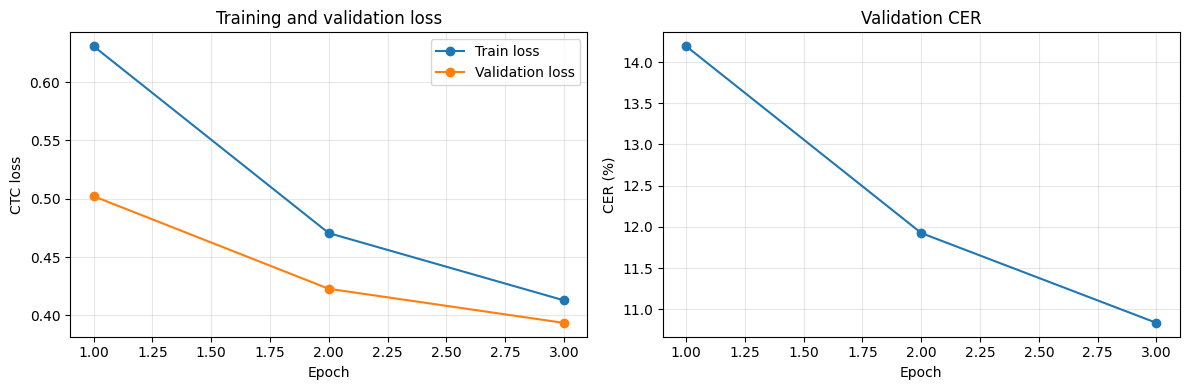


========== EXPORTED FILES ==========
/kaggle/working/fsboard_test_predictions.csv | 0.87 MB
/kaggle/working/fsboard_final_metrics.json | 0.0 MB
/kaggle/working/fsboard_training_curves.png | 0.08 MB
/kaggle/working/bigru_ctc_full_best.pt | 5.29 MB


In [38]:
import os
import csv
import json
import shutil
import zipfile
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from torch.nn.utils.rnn import (
    pack_padded_sequence,
    pad_packed_sequence,
)
from torch.utils.data import Dataset, DataLoader

# ============================================================
# 1. Paths, device, checkpoint
# ============================================================
ROOTS = ["/kaggle/working", "/kaggle/input"]
DATA_DIR = "/kaggle/working/fsboard_processed"
TEST_PATH = os.path.join(DATA_DIR, "fsboard_test_proc_clean.npz")
CHECKPOINT_PATH = "/kaggle/working/bigru_ctc_full_best.pt"

OUTPUT_CSV = "/kaggle/working/fsboard_test_predictions.csv"
OUTPUT_JSON = "/kaggle/working/fsboard_final_metrics.json"
OUTPUT_PLOT = "/kaggle/working/fsboard_training_curves.png"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

if not os.path.exists(CHECKPOINT_PATH):
    raise FileNotFoundError(
        f"Không tìm thấy checkpoint tốt nhất: {CHECKPOINT_PATH}"
    )

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=False,
)

char_to_idx = checkpoint["char_to_idx"]
idx_to_char = checkpoint["idx_to_char"]
blank_idx = checkpoint["blank_idx"]
num_classes = checkpoint["num_classes"]

# ============================================================
# 2. Locate test NPZ or extract only that file from a ZIP
# ============================================================
os.makedirs(DATA_DIR, exist_ok=True)

if not os.path.exists(TEST_PATH):
    found_npz = None
    zip_files = []

    for root in ROOTS:
        for current, _, files in os.walk(root):
            for filename in files:
                full_path = os.path.join(current, filename)

                if filename == "fsboard_test_proc_clean.npz":
                    found_npz = full_path
                    break

                if filename.lower().endswith(".zip"):
                    zip_files.append(full_path)

            if found_npz:
                break
        if found_npz:
            break

    if found_npz:
        TEST_PATH = found_npz
        print("Tìm thấy test NPZ:", TEST_PATH)
    else:
        matching_archive = None
        matching_member = None

        for archive in zip_files:
            try:
                with zipfile.ZipFile(archive, "r") as zf:
                    members = [
                        name for name in zf.namelist()
                        if name.endswith("fsboard_test_proc_clean.npz")
                    ]

                    if members:
                        matching_archive = archive
                        matching_member = members[0]
                        break
            except (zipfile.BadZipFile, OSError):
                continue

        if matching_archive is None:
            raise FileNotFoundError(
                "Không tìm thấy fsboard_test_proc_clean.npz "
                "hoặc ZIP chứa file này trong /kaggle/working "
                "và /kaggle/input."
            )

        print("Archive:", matching_archive)
        print("Extracting:", matching_member)

        with zipfile.ZipFile(matching_archive, "r") as zf:
            with zf.open(matching_member, "r") as src:
                with open(TEST_PATH, "wb") as dst:
                    shutil.copyfileobj(src, dst)

        print("Test NPZ saved:", TEST_PATH)

# ============================================================
# 3. Read and validate the correct signing hand
# ============================================================
def to_text(value):
    if isinstance(value, (bytes, np.bytes_)):
        return value.decode("utf-8")
    return str(value)


test_examples = []
test_stats = {
    "total": 0,
    "missing_hand": 0,
    "empty_pose": 0,
    "invalid_pose": 0,
    "empty_label": 0,
    "unknown_character_labels": 0,
}

with np.load(TEST_PATH, allow_pickle=True) as data:
    left = data["left_hand_poses"]
    right = data["right_hand_poses"]
    hands = data["signing_hand"]
    labels = data["words"]

    test_stats["total"] = len(labels)

    for i in range(len(labels)):
        try:
            hand = int(hands[i])
        except (TypeError, ValueError):
            test_stats["missing_hand"] += 1
            continue

        if hand not in (0, 1):
            test_stats["missing_hand"] += 1
            continue

        # 0 = tay phải; 1 = tay trái
        entry = right[i] if hand == 0 else left[i]

        try:
            pose = np.asarray(entry[0], dtype=np.float32)
        except (KeyError, IndexError, TypeError, ValueError):
            test_stats["empty_pose"] += 1
            continue

        if pose.size == 0:
            test_stats["empty_pose"] += 1
            continue

        if (
            pose.ndim != 3
            or pose.shape[1:] != (21, 3)
            or not np.isfinite(pose).all()
        ):
            test_stats["invalid_pose"] += 1
            continue

        label = to_text(labels[i])

        if not label.strip():
            test_stats["empty_label"] += 1
            continue

        unknown = sorted(set(label) - set(char_to_idx))
        if unknown:
            test_stats["unknown_character_labels"] += 1

        # Không lọc theo số frame CTC ở inference:
        # đây là test dự đoán, không phải tính CTC loss.
        test_examples.append({
            "source_index": i,
            "pose": pose,
            "label": label,
            "hand": hand,
            "unknown_chars": "".join(unknown),
        })

print("\nTest data summary:")
for key, value in test_stats.items():
    print(f"  {key}: {value}")
print("  usable_test_examples:", len(test_examples))

if not test_examples:
    raise RuntimeError("Không còn mẫu test hợp lệ để đánh giá.")

# ============================================================
# 4. Recreate normalization and model
# ============================================================
def normalize_pose(pose):
    pose = np.asarray(pose, dtype=np.float32)

    wrist = pose[:, 0:1, :]
    scale = np.linalg.norm(
        pose[:, 9, :] - pose[:, 0, :],
        axis=1,
    )
    scale = np.maximum(scale, 1.0)

    normalized = (pose - wrist) / scale[:, None, None]
    normalized = np.clip(normalized, -5.0, 5.0)

    return np.ascontiguousarray(
        normalized.reshape(len(pose), 63),
        dtype=np.float32,
    )


class TestDataset(Dataset):
    def __init__(self, examples):
        self.examples = examples

    def __len__(self):
        return len(self.examples)

    def __getitem__(self, index):
        row = self.examples[index]
        features = normalize_pose(row["pose"])
        return (
            torch.from_numpy(features),
            row["label"],
            row["source_index"],
            row["unknown_chars"],
        )


def collate_test(batch):
    features, labels, indices, unknown_chars = zip(*batch)

    lengths = torch.tensor(
        [len(x) for x in features],
        dtype=torch.long,
    )
    max_len = int(lengths.max())

    x = torch.zeros(len(features), max_len, 63)

    for i, feature in enumerate(features):
        x[i, :len(feature)] = feature

    return x, lengths, list(labels), list(indices), list(unknown_chars)


class BiGRUCTC(nn.Module):
    def __init__(self, input_dim, hidden_size, num_layers, num_classes):
        super().__init__()

        self.gru = nn.GRU(
            input_size=input_dim,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True,
            dropout=0.2 if num_layers > 1 else 0.0,
        )
        self.dropout = nn.Dropout(0.2)
        self.classifier = nn.Linear(hidden_size * 2, num_classes)

    def forward(self, x, lengths):
        packed = pack_padded_sequence(
            x,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False,
        )
        packed_out, _ = self.gru(packed)
        out, _ = pad_packed_sequence(
            packed_out,
            batch_first=True,
            total_length=x.shape[1],
        )
        return self.classifier(self.dropout(out)).transpose(0, 1).contiguous()


model = BiGRUCTC(
    input_dim=checkpoint["input_dim"],
    hidden_size=checkpoint["hidden_size"],
    num_layers=checkpoint["num_layers"],
    num_classes=num_classes,
).to(device)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

test_loader = DataLoader(
    TestDataset(test_examples),
    batch_size=16,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
    collate_fn=collate_test,
)

# ============================================================
# 5. Decode predictions and calculate metrics
# ============================================================
def decode_ctc(logits, lengths):
    # logits: (T, B, C)
    frame_ids = logits.argmax(dim=-1)
    predictions = []

    for b, length in enumerate(lengths.tolist()):
        sequence = frame_ids[:length, b].tolist()
        out = []
        previous = blank_idx

        for token in sequence:
            if token != blank_idx and token != previous:
                out.append(idx_to_char[token])
            previous = token

        predictions.append("".join(out))

    return predictions


def edit_distance(a, b):
    previous = list(range(len(b) + 1))

    for i, ca in enumerate(a, start=1):
        current = [i]

        for j, cb in enumerate(b, start=1):
            current.append(min(
                current[-1] + 1,
                previous[j] + 1,
                previous[j - 1] + (ca != cb),
            ))

        previous = current

    return previous[-1]


def word_edit_distance(reference, prediction):
    return edit_distance(reference.split(), prediction.split())


rows = []
total_char_edits = 0
total_reference_chars = 0
total_word_edits = 0
total_reference_words = 0
exact_matches = 0
empty_predictions = 0
nonblank_frames = 0
total_frames = 0

with torch.no_grad():
    for batch_no, batch in enumerate(test_loader, start=1):
        x, lengths, references, indices, unknown_chars = batch
        x = x.to(device, non_blocking=True)

        logits = model(x, lengths)
        predictions = decode_ctc(logits, lengths)

        frame_ids = logits.argmax(dim=-1)

        for b, (reference, prediction) in enumerate(
            zip(references, predictions)
        ):
            frame_count = int(lengths[b])
            nonblank_frames += int(
                (frame_ids[:frame_count, b] != blank_idx).sum().item()
            )
            total_frames += frame_count

            char_edits = edit_distance(reference, prediction)
            ref_chars = len(reference)

            word_edits = word_edit_distance(reference, prediction)
            ref_words = len(reference.split())

            total_char_edits += char_edits
            total_reference_chars += ref_chars
            total_word_edits += word_edits
            total_reference_words += ref_words

            exact = reference == prediction
            exact_matches += int(exact)
            empty_predictions += int(prediction == "")

            rows.append({
                "source_index": indices[b],
                "signing_hand": (
                    test_examples[len(rows)]["hand"]
                    if len(rows) < len(test_examples) else None
                ),
                "reference": reference,
                "prediction": prediction,
                "char_edits": char_edits,
                "reference_characters": ref_chars,
                "cer": char_edits / max(ref_chars, 1),
                "word_edits": word_edits,
                "reference_words": ref_words,
                "exact_match": exact,
                "unknown_reference_characters": unknown_chars[b],
            })

        if batch_no % 200 == 0:
            print(f"Processed test: {batch_no}/{len(test_loader)} batches")

n = len(rows)

metrics = {
    "checkpoint": CHECKPOINT_PATH,
    "checkpoint_epoch": checkpoint.get("epoch"),
    "n_test": n,
    "character_error_rate": total_char_edits / max(total_reference_chars, 1),
    "word_error_rate": total_word_edits / max(total_reference_words, 1),
    "exact_match_accuracy": exact_matches / max(n, 1),
    "empty_prediction_rate": empty_predictions / max(n, 1),
    "argmax_nonblank_frame_rate": nonblank_frames / max(total_frames, 1),
    "test_data_stats": test_stats,
    "note": (
        "CER/WER use greedy CTC decoding; test was evaluated after model "
        "selection on validation. Keep test results separate from tuning."
    ),
}

with open(OUTPUT_CSV, "w", newline="", encoding="utf-8-sig") as f:
    writer = csv.DictWriter(f, fieldnames=list(rows[0].keys()))
    writer.writeheader()
    writer.writerows(rows)

with open(OUTPUT_JSON, "w", encoding="utf-8") as f:
    json.dump(metrics, f, ensure_ascii=False, indent=2)

print("\n========== OFFICIAL TEST RESULTS ==========")
print("N:", n)
print("CER:", f"{100 * metrics['character_error_rate']:.2f}%")
print("WER:", f"{100 * metrics['word_error_rate']:.2f}%")
print("Exact match accuracy:", f"{100 * metrics['exact_match_accuracy']:.2f}%")
print("Empty prediction rate:", f"{100 * metrics['empty_prediction_rate']:.2f}%")
print(
    "Nonblank frame rate:",
    f"{100 * metrics['argmax_nonblank_frame_rate']:.2f}%"
)

print("\nSample predictions:")
for row in rows[:10]:
    print("TRUE:", repr(row["reference"]))
    print("PRED:", repr(row["prediction"]))
    print()

# ============================================================
# 6. Save learning curves from checkpoint
# ============================================================
history = checkpoint.get("history", [])

if history:
    epochs = [item["epoch"] for item in history]
    train_losses = [item["train_loss"] for item in history]
    val_losses = [item["val_loss"] for item in history]
    val_cers = [100 * item["val_cer"] for item in history]

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(epochs, train_losses, marker="o", label="Train loss")
    axes[0].plot(epochs, val_losses, marker="o", label="Validation loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("CTC loss")
    axes[0].set_title("Training and validation loss")
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(epochs, val_cers, marker="o")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("CER (%)")
    axes[1].set_title("Validation CER")
    axes[1].grid(True, alpha=0.3)

    fig.tight_layout()
    fig.savefig(OUTPUT_PLOT, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)

print("\n========== EXPORTED FILES ==========")
for path in [OUTPUT_CSV, OUTPUT_JSON, OUTPUT_PLOT, CHECKPOINT_PATH]:
    if os.path.exists(path):
        print(path, "|", round(os.path.getsize(path) / (1024 ** 2), 2), "MB")

In [39]:
import zipfile
import os
from IPython.display import FileLink, display

files = [
    "/kaggle/working/fsboard_training_curves.png",
    "/kaggle/working/fsboard_test_predictions.csv",
    "/kaggle/working/fsboard_final_metrics.json",
    "/kaggle/working/bigru_ctc_full_best.pt",
]

zip_path = "/kaggle/working/day3_results.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for path in files:
        if os.path.exists(path):
            z.write(path, arcname=os.path.basename(path))
            print("Đã thêm:", os.path.basename(path))
        else:
            print("Không tìm thấy:", path)

print("\nBấm link dưới đây để tải:")
display(FileLink(zip_path))

Đã thêm: fsboard_training_curves.png
Đã thêm: fsboard_test_predictions.csv
Đã thêm: fsboard_final_metrics.json
Đã thêm: bigru_ctc_full_best.pt

Bấm link dưới đây để tải:


/kaggle/working/day3_results.zip

In [40]:
import os
import zipfile
from IPython.display import FileLink, display

files = [
    "/kaggle/working/fsboard_training_curves.png",
    "/kaggle/working/fsboard_test_predictions.csv",
    "/kaggle/working/fsboard_final_metrics.json",
    "/kaggle/working/bigru_ctc_full_best.pt",
]

zip_path = "/kaggle/working/day3_results.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for path in files:
        if os.path.isfile(path):
            z.write(path, arcname=os.path.basename(path))
            print("OK:", os.path.basename(path))
        else:
            print("MISSING:", path)

print("\nZIP tồn tại:", os.path.isfile(zip_path))
print("Dung lượng (MB):", round(os.path.getsize(zip_path) / 1024**2, 2))

# Dùng đường dẫn tương đối thay vì đường dẫn tuyệt đối
display(FileLink("day3_results.zip"))

OK: fsboard_training_curves.png
OK: fsboard_test_predictions.csv
OK: fsboard_final_metrics.json
OK: bigru_ctc_full_best.pt

ZIP tồn tại: True
Dung lượng (MB): 5.22


/kaggle/working/day3_results.zip

Device: cuda
Train / validation / test: 126045 12005 12515
Warm-up batches: 400
Full train batches per epoch: 7878
Warm-up 100/400 | loss=3.6051
Warm-up 200/400 | loss=3.4421
Warm-up 300/400 | loss=3.2397
Warm-up 400/400 | loss=3.0729
Epoch 1/3 | step 1000/7878 | recent loss=1.5294
Epoch 1/3 | step 2000/7878 | recent loss=0.9966
Epoch 1/3 | step 3000/7878 | recent loss=0.7911
Epoch 1/3 | step 4000/7878 | recent loss=0.7088
Epoch 1/3 | step 5000/7878 | recent loss=0.6479
Epoch 1/3 | step 6000/7878 | recent loss=0.6161
Epoch 1/3 | step 7000/7878 | recent loss=0.5812

MOTION EPOCH 1/3
Train loss: 0.9190
Validation loss: 0.5175
Validation CER: 14.28%
Epoch time: 6.3 min

Epoch 2/3 | step 1000/7878 | recent loss=0.5252
Epoch 2/3 | step 2000/7878 | recent loss=0.5117
Epoch 2/3 | step 3000/7878 | recent loss=0.4974
Epoch 2/3 | step 4000/7878 | recent loss=0.4760
Epoch 2/3 | step 5000/7878 | recent loss=0.4520
Epoch 2/3 | step 6000/7878 | recent loss=0.4763
Epoch 2/3 | step 7000/7878 | recent 

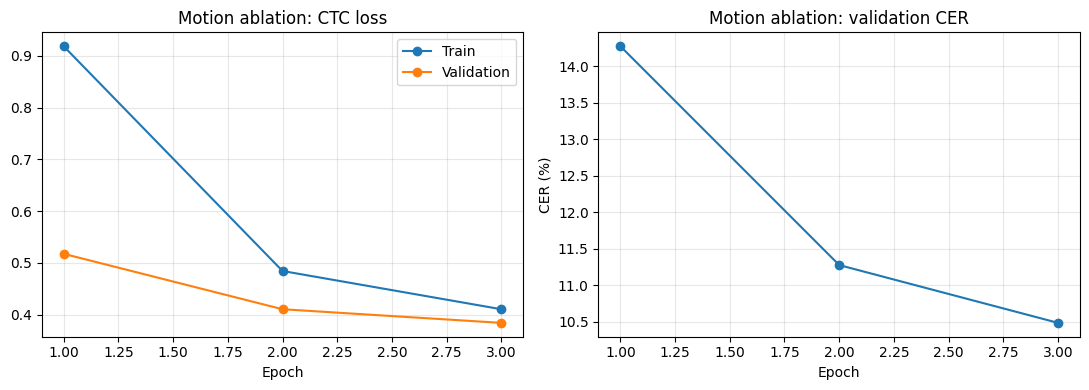


========== DAY 5 ABLATION COMPARISON ==========
Model                           Val CER    Test CER    Test WER   Exact match
Hand-only (63D)                  10.95%      10.41%      57.13%        33.10%
Hand + motion (126D)             10.48%      10.26%      56.33%        33.35%

Best motion checkpoint: /kaggle/working/bigru_ctc_motion_best.pt
Latest motion checkpoint: /kaggle/working/bigru_ctc_motion_latest.pt
Metrics JSON: /kaggle/working/task3_day5_ablation_metrics.json
Predictions CSV: /kaggle/working/task3_day5_motion_predictions.csv
Curve PNG: /kaggle/working/task3_day5_ablation_curve.png
Total time: 19.5 min


In [41]:
import os, csv, json, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from torch.utils.data import Dataset, DataLoader, Subset
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence

# ==========================================================
# DAY 5 — ABLATION: HAND-ONLY vs HAND + MOTION FEATURES
# Run in the same Kaggle notebook kernel as Days 3–4.
# ==========================================================

SEED = 42
BATCH_SIZE = 16
WARMUP_SAMPLES = 6400
FULL_EPOCHS = 3
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

for name in ["train_examples", "val_examples", "test_examples",
             "char_to_idx", "idx_to_char"]:
    if name not in globals():
        raise RuntimeError(
            f"Thiếu biến {name}. Hãy chạy trong kernel Kaggle đã dùng "
            "để huấn luyện và đánh giá baseline Day 3–4."
        )

if not os.path.exists("/kaggle/working/bigru_ctc_full_best.pt"):
    raise FileNotFoundError("Không tìm thấy checkpoint baseline Day 3–4.")

BLANK = 0
NUM_CLASSES = len(char_to_idx) + 1

# ----------------------------
# 1. Feature preprocessing
# ----------------------------
def normalize_hand(pose):
    pose = np.asarray(pose, dtype=np.float32)
    wrist = pose[:, 0:1, :]
    scale = np.linalg.norm(pose[:, 9, :] - pose[:, 0, :], axis=1)
    scale = np.maximum(scale, 1.0)

    x = (pose - wrist) / scale[:, None, None]
    x = np.clip(x, -5.0, 5.0)
    return np.ascontiguousarray(x.reshape(len(pose), 63), dtype=np.float32)

def add_motion_features(pose):
    x = normalize_hand(pose)
    velocity = np.zeros_like(x)
    velocity[1:] = x[1:] - x[:-1]
    velocity = np.clip(velocity, -5.0, 5.0)
    return np.ascontiguousarray(
        np.concatenate([x, velocity], axis=1),
        dtype=np.float32
    )

# ----------------------------
# 2. Dataset and batching
# ----------------------------
def to_text(value):
    if isinstance(value, bytes):
        return value.decode("utf-8")
    return str(value)

class MotionDataset(Dataset):
    def __init__(self, examples):
        self.examples = examples

    def __len__(self):
        return len(self.examples)

    def __getitem__(self, i):
        item = self.examples[i]
        if isinstance(item, dict):
            pose, text = item["pose"], item["label"]
        else:
            pose, text = item[0], item[1]

        x = add_motion_features(pose)
        y = np.asarray([char_to_idx[c] for c in text], dtype=np.int64)
        return torch.from_numpy(x), torch.from_numpy(y), text

def collate_motion(batch):
    xs, ys, texts = zip(*batch)
    lengths = torch.tensor([len(x) for x in xs], dtype=torch.long)
    target_lengths = torch.tensor([len(y) for y in ys], dtype=torch.long)
    padded = torch.zeros(len(xs), int(lengths.max()), 126, dtype=torch.float32)

    for i, x in enumerate(xs):
        padded[i, :len(x)] = x

    return padded, torch.cat(ys), lengths, target_lengths, list(texts)

train_ds = MotionDataset(train_examples)
val_ds = MotionDataset(val_examples)
test_ds = MotionDataset(test_examples)

rng = np.random.default_rng(SEED)
warm_ids = rng.choice(
    len(train_ds), min(WARMUP_SAMPLES, len(train_ds)), replace=False
).tolist()

warm_loader = DataLoader(
    Subset(train_ds, warm_ids),
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_motion,
    num_workers=0,
    generator=torch.Generator().manual_seed(SEED),
)
train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=True,
    collate_fn=collate_motion, num_workers=0,
    generator=torch.Generator().manual_seed(SEED),
)
val_loader = DataLoader(
    val_ds, batch_size=BATCH_SIZE, shuffle=False,
    collate_fn=collate_motion, num_workers=0,
)
test_loader = DataLoader(
    test_ds, batch_size=BATCH_SIZE, shuffle=False,
    collate_fn=collate_motion, num_workers=0,
)

# ----------------------------
# 3. Same model family, 126D input
# ----------------------------
class BiGRUMotionCTC(nn.Module):
    def __init__(self):
        super().__init__()
        self.gru = nn.GRU(
            input_size=126,
            hidden_size=128,
            num_layers=2,
            batch_first=True,
            bidirectional=True,
            dropout=0.2,
        )
        self.dropout = nn.Dropout(0.2)
        self.classifier = nn.Linear(256, NUM_CLASSES)

    def forward(self, x, lengths):
        packed = pack_padded_sequence(
            x, lengths.cpu(), batch_first=True, enforce_sorted=False
        )
        packed_out, _ = self.gru(packed)
        out, _ = pad_packed_sequence(
            packed_out, batch_first=True, total_length=x.shape[1]
        )
        return self.classifier(self.dropout(out)).transpose(0, 1).contiguous()

model = BiGRUMotionCTC().to(DEVICE)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
ctc = nn.CTCLoss(blank=BLANK, zero_infinity=True)

def greedy_decode(log_probs, lengths):
    ids = log_probs.argmax(dim=-1)
    results = []

    for b, length in enumerate(lengths.tolist()):
        output, previous = [], BLANK
        for token in ids[:length, b].tolist():
            if token != BLANK and token != previous:
                output.append(idx_to_char[token])
            previous = token
        results.append("".join(output))

    return results

def edit_distance(a, b):
    prev = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        cur = [i]
        for j, cb in enumerate(b, 1):
            cur.append(min(
                cur[-1] + 1, prev[j] + 1,
                prev[j - 1] + (ca != cb)
            ))
        prev = cur
    return prev[-1]

def evaluate(loader, write_predictions=False):
    model.eval()
    loss_sum, batches = 0.0, 0
    edits = chars = word_edits = words = exact = 0
    records = []

    with torch.no_grad():
        for x, targets, lengths, target_lengths, texts in loader:
            x = x.to(DEVICE)
            targets = targets.to(DEVICE)

            logits = model(x, lengths)
            log_probs = F.log_softmax(logits, dim=-1).contiguous()
            loss = ctc(log_probs, targets, lengths, target_lengths)
            loss_sum += float(loss.cpu())
            batches += 1

            preds = greedy_decode(log_probs, lengths)
            for truth, pred in zip(texts, preds):
                edits += edit_distance(truth, pred)
                chars += len(truth)
                word_edits += edit_distance(truth.split(), pred.split())
                words += len(truth.split())
                exact += int(truth == pred)
                if write_predictions:
                    records.append({"reference": truth, "prediction": pred})

    n = len(loader.dataset)
    return {
        "loss": loss_sum / max(batches, 1),
        "cer": edits / max(chars, 1),
        "wer": word_edits / max(words, 1),
        "exact_match": exact / max(n, 1),
        "predictions": records,
    }

# ----------------------------
# 4. Warm-up on same-sized subset
# ----------------------------
print("Device:", DEVICE)
print("Train / validation / test:",
      len(train_ds), len(val_ds), len(test_ds))
print("Warm-up batches:", len(warm_loader))
print("Full train batches per epoch:", len(train_loader))

start = time.time()
model.train()
warm_losses = []

for step, (x, targets, lengths, target_lengths, texts) in enumerate(warm_loader, 1):
    x, targets = x.to(DEVICE), targets.to(DEVICE)
    optimizer.zero_grad(set_to_none=True)
    log_probs = F.log_softmax(model(x, lengths), dim=-1).contiguous()
    loss = ctc(log_probs, targets, lengths, target_lengths)

    if not torch.isfinite(loss):
        raise RuntimeError(f"Warm-up loss không hữu hạn tại step {step}")

    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
    optimizer.step()
    warm_losses.append(float(loss.detach().cpu()))

    if step % 100 == 0:
        print(f"Warm-up {step}/{len(warm_loader)} | loss={np.mean(warm_losses[-50:]):.4f}")

# Same learning-rate schedule as baseline fine-tuning
for group in optimizer.param_groups:
    group["lr"] = 5e-4

# ----------------------------
# 5. Full-data training, select by validation CER
# ----------------------------
history = []
best_cer = float("inf")
best_path = "/kaggle/working/bigru_ctc_motion_best.pt"
latest_path = "/kaggle/working/bigru_ctc_motion_latest.pt"

for epoch in range(1, FULL_EPOCHS + 1):
    model.train()
    losses = []
    epoch_start = time.time()

    for step, (x, targets, lengths, target_lengths, texts) in enumerate(train_loader, 1):
        x, targets = x.to(DEVICE), targets.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)

        log_probs = F.log_softmax(model(x, lengths), dim=-1).contiguous()
        loss = ctc(log_probs, targets, lengths, target_lengths)

        if not torch.isfinite(loss):
            raise RuntimeError(f"Training loss không hữu hạn tại epoch {epoch}, step {step}")

        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
        optimizer.step()
        losses.append(float(loss.detach().cpu()))

        if step % 1000 == 0:
            print(
                f"Epoch {epoch}/{FULL_EPOCHS} | "
                f"step {step}/{len(train_loader)} | "
                f"recent loss={np.mean(losses[-100:]):.4f}"
            )

    val_metrics = evaluate(val_loader)
    row = {
        "epoch": epoch,
        "train_loss": float(np.mean(losses)),
        "val_loss": val_metrics["loss"],
        "val_cer": val_metrics["cer"],
        "val_wer": val_metrics["wer"],
        "val_exact_match": val_metrics["exact_match"],
    }
    history.append(row)

    payload = {
        "model_state_dict": model.state_dict(),
        "char_to_idx": char_to_idx,
        "idx_to_char": idx_to_char,
        "blank_idx": BLANK,
        "input_dim": 126,
        "hidden_size": 128,
        "num_layers": 2,
        "num_classes": NUM_CLASSES,
        "epoch": epoch,
        "history": history,
    }
    torch.save(payload, latest_path)

    if val_metrics["cer"] < best_cer:
        best_cer = val_metrics["cer"]
        torch.save(payload, best_path)

    print(f"\nMOTION EPOCH {epoch}/{FULL_EPOCHS}")
    print(f"Train loss: {row['train_loss']:.4f}")
    print(f"Validation loss: {row['val_loss']:.4f}")
    print(f"Validation CER: {100 * row['val_cer']:.2f}%")
    print(f"Epoch time: {(time.time() - epoch_start)/60:.1f} min\n")

# ----------------------------
# 6. Test the checkpoint selected by validation only
# ----------------------------
payload = torch.load(best_path, map_location=DEVICE, weights_only=False)
model.load_state_dict(payload["model_state_dict"])

test_metrics = evaluate(test_loader, write_predictions=True)
test_predictions = test_metrics.pop("predictions")

with open("/kaggle/working/task3_day5_motion_predictions.csv", "w",
          newline="", encoding="utf-8-sig") as f:
    writer = csv.DictWriter(f, fieldnames=["reference", "prediction"])
    writer.writeheader()
    writer.writerows(test_predictions)

baseline = {
    "features": "Hand-only (63D)",
    "val_cer": 0.1095,
    "test_cer": 0.1041,
    "test_wer": 0.5713,
    "test_exact_match": 0.3310,
}
motion = {
    "features": "Hand + motion (126D)",
    "best_epoch": payload["epoch"],
    "val_cer": best_cer,
    "test_cer": test_metrics["cer"],
    "test_wer": test_metrics["wer"],
    "test_exact_match": test_metrics["exact_match"],
}

results = {
    "baseline_hand_only": baseline,
    "motion_ablation": motion,
    "history": history,
    "selection_rule": "Best epoch selected using validation CER",
    "notes": [
        "Both models use the same official FSboard split.",
        "The existing baseline was initialized by subset warm-up before full-data training.",
        "The motion ablation uses the same warm-up sample count, then three full-data epochs.",
        "Test metrics are reported for comparison, not used for checkpoint selection."
    ]
}

with open("/kaggle/working/task3_day5_ablation_metrics.json", "w",
          encoding="utf-8") as f:
    json.dump(results, f, ensure_ascii=False, indent=2)

# Learning curves for the ablation model
epochs = [x["epoch"] for x in history]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(epochs, [x["train_loss"] for x in history], marker="o", label="Train")
axes[0].plot(epochs, [x["val_loss"] for x in history], marker="o", label="Validation")
axes[0].set_title("Motion ablation: CTC loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(epochs, [100*x["val_cer"] for x in history], marker="o")
axes[1].set_title("Motion ablation: validation CER")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("CER (%)")
axes[1].grid(alpha=0.3)

fig.tight_layout()
fig.savefig("/kaggle/working/task3_day5_ablation_curve.png", dpi=160)
plt.show()
plt.close(fig)

print("\n========== DAY 5 ABLATION COMPARISON ==========")
print(f"{'Model':<27}{'Val CER':>12}{'Test CER':>12}{'Test WER':>12}{'Exact match':>14}")
for r in [baseline, motion]:
    print(
        f"{r['features']:<27}"
        f"{100*r['val_cer']:>11.2f}%"
        f"{100*r['test_cer']:>11.2f}%"
        f"{100*r['test_wer']:>11.2f}%"
        f"{100*r['test_exact_match']:>13.2f}%"
    )

print("\nBest motion checkpoint:", best_path)
print("Latest motion checkpoint:", latest_path)
print("Metrics JSON: /kaggle/working/task3_day5_ablation_metrics.json")
print("Predictions CSV: /kaggle/working/task3_day5_motion_predictions.csv")
print("Curve PNG: /kaggle/working/task3_day5_ablation_curve.png")
print(f"Total time: {(time.time()-start)/60:.1f} min")

In [42]:
import os
import zipfile
from IPython.display import FileLink, display

files = [
    "/kaggle/working/task3_day5_ablation_metrics.json",
    "/kaggle/working/task3_day5_motion_predictions.csv",
    "/kaggle/working/task3_day5_ablation_curve.png",
]

# Kiểm tra các file đã tồn tại
missing = [f for f in files if not os.path.isfile(f)]

if missing:
    print("Không tìm thấy các file sau:")
    for f in missing:
        print(f)
else:
    zip_path = "/kaggle/working/day5_ablation_results.zip"

    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
        for f in files:
            z.write(f, arcname=os.path.basename(f))
            print("Đã thêm:", os.path.basename(f))

    os.chdir("/kaggle/working")
    print("\nĐã tạo ZIP. Bấm link bên dưới để tải:")
    display(FileLink("day5_ablation_results.zip"))

Đã thêm: task3_day5_ablation_metrics.json
Đã thêm: task3_day5_motion_predictions.csv
Đã thêm: task3_day5_ablation_curve.png

Đã tạo ZIP. Bấm link bên dưới để tải:


/kaggle/working/day5_ablation_results.zip

Test rows: 12515
Hai file dự đoán được căn chỉnh theo cùng thứ tự mẫu.

========== DAY 6: OVERALL ERROR ANALYSIS ==========

Hand-only (63D)
  CER: 10.44%
  WER: 57.71%
  Exact match: 32.34%
  S=6,495, D=12,242, I=4,329
  Space-related edits: 4,675
  Digit-related edits: 4,238
  Punctuation-related edits: 3,257

Hand + motion (126D)
  CER: 10.26%
  WER: 56.33%
  Exact match: 33.35%
  S=6,603, D=11,813, I=4,254
  Space-related edits: 4,390
  Digit-related edits: 4,011
  Punctuation-related edits: 3,074

========== CER BY PHRASE LENGTH ==========

Hand-only (63D)
   <=10: n=  731, CER=13.76%, WER=63.20%
  11-20: n= 7802, CER=10.55%, WER=56.46%
  21-30: n= 3982, CER=10.08%, WER=59.03%
    >30: n=    0, CER=0.00%, WER=0.00%

Hand + motion (126D)
   <=10: n=  731, CER=13.93%, WER=61.68%
  11-20: n= 7802, CER=10.20%, WER=54.69%
  21-30: n= 3982, CER=10.08%, WER=58.34%
    >30: n=    0, CER=0.00%, WER=0.00%


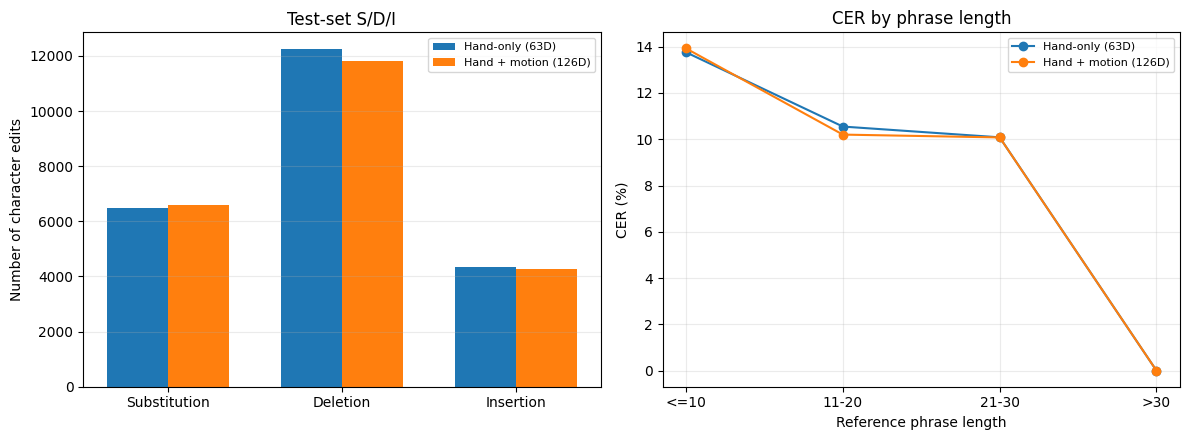


========== DAY 6: RUNTIME ==========
Device: cuda
GPU: Tesla T4
CPU feature preprocessing sample mean: 0.227 ms/clip
Model forward mean: 17.08 ms/batch
Model forward p50 / p95: 17.30 / 21.86 ms/batch
Approx model forward per clip: 1.07 ms

========== EXPORTED DAY 6 FILES ==========
/kaggle/working/task3_day6_error_by_group.csv | 2.7 KB
/kaggle/working/task3_day6_sample_errors.csv | 2814.7 KB
/kaggle/working/task3_day6_top_error_cases.csv | 11.7 KB
/kaggle/working/task3_day6_summary.json | 1.9 KB
/kaggle/working/task3_day6_error_runtime.png | 83.6 KB


In [43]:
# ============================================================
# DAY 6 — ERROR ANALYSIS + RUNTIME
# Compare Hand-only vs Hand + Motion on the same test examples.
# ============================================================

import os
import csv
import json
import time
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence

BASELINE_CSV = "/kaggle/working/fsboard_test_predictions.csv"
MOTION_CSV = "/kaggle/working/task3_day5_motion_predictions.csv"
MOTION_CHECKPOINT = "/kaggle/working/bigru_ctc_motion_best.pt"

OUT_DIR = "/kaggle/working"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

for path in [BASELINE_CSV, MOTION_CSV, MOTION_CHECKPOINT]:
    if not os.path.exists(path):
        raise FileNotFoundError(f"Không tìm thấy file: {path}")

# ------------------------------------------------------------
# 1. Load test predictions and verify alignment
# ------------------------------------------------------------
def read_predictions(path):
    with open(path, "r", encoding="utf-8-sig", newline="") as f:
        rows = list(csv.DictReader(f))

    required = {"reference", "prediction"}
    if not rows or not required.issubset(rows[0].keys()):
        raise ValueError(f"CSV thiếu cột cần thiết: {path}")

    return [
        {
            "reference": row["reference"],
            "prediction": row["prediction"],
        }
        for row in rows
    ]


baseline_rows = read_predictions(BASELINE_CSV)
motion_rows = read_predictions(MOTION_CSV)

if len(baseline_rows) != len(motion_rows):
    raise ValueError(
        f"Số mẫu không khớp: baseline={len(baseline_rows)}, "
        f"motion={len(motion_rows)}"
    )

for i, (a, b) in enumerate(zip(baseline_rows, motion_rows)):
    if a["reference"] != b["reference"]:
        raise ValueError(
            f"Nhãn tham chiếu không khớp ở hàng {i}; "
            "không thể so sánh trực tiếp hai CSV."
        )

print("Test rows:", len(baseline_rows))
print("Hai file dự đoán được căn chỉnh theo cùng thứ tự mẫu.")

# ------------------------------------------------------------
# 2. Levenshtein alignment: substitutions/deletions/insertions
# ------------------------------------------------------------
def align_edit_operations(reference, prediction):
    """
    Trả về danh sách phép căn chỉnh tối thiểu.
    M: match, S: substitution, D: deletion, I: insertion.
    """
    n, m = len(reference), len(prediction)
    dp = [[0] * (m + 1) for _ in range(n + 1)]

    for i in range(n + 1):
        dp[i][0] = i
    for j in range(m + 1):
        dp[0][j] = j

    for i in range(1, n + 1):
        rc = reference[i - 1]
        for j in range(1, m + 1):
            pc = prediction[j - 1]
            dp[i][j] = min(
                dp[i - 1][j] + 1,
                dp[i][j - 1] + 1,
                dp[i - 1][j - 1] + (rc != pc),
            )

    operations = []
    i, j = n, m

    while i > 0 or j > 0:
        # Ưu tiên căn chỉnh chéo, bao gồm match/substitution.
        if i > 0 and j > 0:
            cost = int(reference[i - 1] != prediction[j - 1])
            if dp[i][j] == dp[i - 1][j - 1] + cost:
                if cost:
                    operations.append(
                        ("S", reference[i - 1], prediction[j - 1])
                    )
                else:
                    operations.append(
                        ("M", reference[i - 1], prediction[j - 1])
                    )
                i -= 1
                j -= 1
                continue

        if i > 0 and dp[i][j] == dp[i - 1][j] + 1:
            operations.append(("D", reference[i - 1], ""))
            i -= 1
        else:
            operations.append(("I", "", prediction[j - 1]))
            j -= 1

    operations.reverse()
    return operations


def edit_distance_tokens(a, b):
    prev = list(range(len(b) + 1))

    for i, x in enumerate(a, start=1):
        cur = [i]
        for j, y in enumerate(b, start=1):
            cur.append(min(
                cur[-1] + 1,
                prev[j] + 1,
                prev[j - 1] + (x != y),
            ))
        prev = cur

    return prev[-1]


def char_kind(c):
    if c == " ":
        return "space"
    if c.isdigit():
        return "digit"
    if c.isalpha():
        return "letter"
    if c:
        return "punctuation_or_symbol"
    return "none"


def analyze_one(reference, prediction):
    operations = align_edit_operations(reference, prediction)
    counts = {op: 0 for op in ["S", "D", "I"]}

    special_errors = {
        "space": 0,
        "digit": 0,
        "punctuation_or_symbol": 0,
    }

    for op, ref_char, pred_char in operations:
        if op in counts:
            counts[op] += 1

        if op == "S":
            relevant = [ref_char, pred_char]
        elif op == "D":
            relevant = [ref_char]
        elif op == "I":
            relevant = [pred_char]
        else:
            continue

        kinds = {char_kind(c) for c in relevant}

        # Count operations affecting whitespace, digits, punctuation.
        for kind in special_errors:
            if kind in kinds:
                special_errors[kind] += 1

    word_edits = edit_distance_tokens(
        reference.split(),
        prediction.split(),
    )
    ref_words = len(reference.split())

    return {
        "char_edits": counts["S"] + counts["D"] + counts["I"],
        "S": counts["S"],
        "D": counts["D"],
        "I": counts["I"],
        "word_edits": word_edits,
        "ref_chars": len(reference),
        "ref_words": ref_words,
        "exact_match": int(reference == prediction),
        "space_edits": special_errors["space"],
        "digit_edits": special_errors["digit"],
        "punctuation_edits": special_errors["punctuation_or_symbol"],
    }


# ------------------------------------------------------------
# 3. Build per-sample error table for both models
# ------------------------------------------------------------
def phrase_flags(text):
    return {
        "contains_space": " " in text,
        "contains_digit": any(c.isdigit() for c in text),
        "contains_punctuation": any(
            not c.isalnum() and not c.isspace() for c in text
        ),
        "has_adjacent_repeat": any(
            text[i] == text[i - 1] for i in range(1, len(text))
        ),
    }


def make_sample_rows(prediction_rows, model_name):
    result = []

    for idx, row in enumerate(prediction_rows):
        ref = row["reference"]
        pred = row["prediction"]
        m = analyze_one(ref, pred)
        flags = phrase_flags(ref)

        length = len(ref)
        if length <= 10:
            length_bin = "<=10"
        elif length <= 20:
            length_bin = "11-20"
        elif length <= 30:
            length_bin = "21-30"
        else:
            length_bin = ">30"

        result.append({
            "model": model_name,
            "sample_index": idx,
            "reference": ref,
            "prediction": pred,
            "phrase_length": length,
            "length_bin": length_bin,
            **m,
            **flags,
        })

    return result


all_rows = (
    make_sample_rows(baseline_rows, "Hand-only (63D)")
    + make_sample_rows(motion_rows, "Hand + motion (126D)")
)

# ------------------------------------------------------------
# 4. Overall metrics, including S/D/I and error subtypes
# ------------------------------------------------------------
def summarize(rows):
    n = len(rows)
    total_chars = sum(r["ref_chars"] for r in rows)
    total_words = sum(r["ref_words"] for r in rows)
    total_edits = sum(r["char_edits"] for r in rows)
    total_word_edits = sum(r["word_edits"] for r in rows)

    return {
        "n_samples": n,
        "reference_characters": total_chars,
        "reference_words": total_words,
        "S": sum(r["S"] for r in rows),
        "D": sum(r["D"] for r in rows),
        "I": sum(r["I"] for r in rows),
        "character_edits": total_edits,
        "CER": total_edits / max(total_chars, 1),
        "word_edits": total_word_edits,
        "WER": total_word_edits / max(total_words, 1),
        "exact_match_accuracy": (
            sum(r["exact_match"] for r in rows) / max(n, 1)
        ),
        "space_related_edits": sum(r["space_edits"] for r in rows),
        "digit_related_edits": sum(r["digit_edits"] for r in rows),
        "punctuation_related_edits": sum(
            r["punctuation_edits"] for r in rows
        ),
    }


model_names = ["Hand-only (63D)", "Hand + motion (126D)"]
overall = {
    name: summarize([r for r in all_rows if r["model"] == name])
    for name in model_names
}

print("\n========== DAY 6: OVERALL ERROR ANALYSIS ==========")
for name in model_names:
    s = overall[name]
    print(f"\n{name}")
    print(f"  CER: {100*s['CER']:.2f}%")
    print(f"  WER: {100*s['WER']:.2f}%")
    print(f"  Exact match: {100*s['exact_match_accuracy']:.2f}%")
    print(f"  S={s['S']:,}, D={s['D']:,}, I={s['I']:,}")
    print(f"  Space-related edits: {s['space_related_edits']:,}")
    print(f"  Digit-related edits: {s['digit_related_edits']:,}")
    print(f"  Punctuation-related edits: {s['punctuation_related_edits']:,}")

# ------------------------------------------------------------
# 5. Error analysis by phrase length and phrase characteristics
# ------------------------------------------------------------
group_rows = []

def append_group_summary(model_name, group_type, group_name, rows):
    s = summarize(rows)
    group_rows.append({
        "model": model_name,
        "group_type": group_type,
        "group": group_name,
        "n_samples": s["n_samples"],
        "reference_characters": s["reference_characters"],
        "character_edits": s["character_edits"],
        "CER": s["CER"],
        "WER": s["WER"],
        "exact_match_accuracy": s["exact_match_accuracy"],
        "S": s["S"],
        "D": s["D"],
        "I": s["I"],
        "space_related_edits": s["space_related_edits"],
        "digit_related_edits": s["digit_related_edits"],
        "punctuation_related_edits": s["punctuation_related_edits"],
    })


length_bins = ["<=10", "11-20", "21-30", ">30"]
flag_groups = [
    ("contains_space", "Contains space"),
    ("contains_digit", "Contains digit"),
    ("contains_punctuation", "Contains punctuation/symbol"),
    ("has_adjacent_repeat", "Has adjacent repeated characters"),
]

for name in model_names:
    rows_for_model = [r for r in all_rows if r["model"] == name]

    append_group_summary(name, "all", "All test samples", rows_for_model)

    for bin_name in length_bins:
        append_group_summary(
            name, "phrase_length", bin_name,
            [r for r in rows_for_model if r["length_bin"] == bin_name],
        )

    for flag, display_name in flag_groups:
        append_group_summary(
            name, "phrase_characteristic", display_name,
            [r for r in rows_for_model if r[flag]],
        )

GROUP_CSV = f"{OUT_DIR}/task3_day6_error_by_group.csv"
with open(GROUP_CSV, "w", newline="", encoding="utf-8-sig") as f:
    writer = csv.DictWriter(f, fieldnames=list(group_rows[0].keys()))
    writer.writeheader()
    writer.writerows(group_rows)

# Detailed sample-level errors
sample_csv = f"{OUT_DIR}/task3_day6_sample_errors.csv"
fields = [
    "model", "sample_index", "reference", "prediction",
    "phrase_length", "length_bin", "char_edits", "S", "D", "I",
    "word_edits", "ref_chars", "ref_words", "exact_match",
    "space_edits", "digit_edits", "punctuation_edits",
    "contains_space", "contains_digit", "contains_punctuation",
    "has_adjacent_repeat",
]
with open(sample_csv, "w", newline="", encoding="utf-8-sig") as f:
    writer = csv.DictWriter(f, fieldnames=fields)
    writer.writeheader()
    writer.writerows(all_rows)

# Top 100 highest-CER sample instances for inspection
top_rows = sorted(
    all_rows,
    key=lambda r: (
        r["char_edits"] / max(r["ref_chars"], 1),
        r["char_edits"],
    ),
    reverse=True,
)[:100]

top_csv = f"{OUT_DIR}/task3_day6_top_error_cases.csv"
with open(top_csv, "w", newline="", encoding="utf-8-sig") as f:
    writer = csv.DictWriter(f, fieldnames=fields)
    writer.writeheader()
    writer.writerows(top_rows)

print("\n========== CER BY PHRASE LENGTH ==========")
for name in model_names:
    print(f"\n{name}")
    for b in length_bins:
        match = next(
            r for r in group_rows
            if r["model"] == name
            and r["group_type"] == "phrase_length"
            and r["group"] == b
        )
        print(
            f"  {b:>5}: n={match['n_samples']:>5}, "
            f"CER={100*match['CER']:.2f}%, "
            f"WER={100*match['WER']:.2f}%"
        )

# ------------------------------------------------------------
# 6. Runtime measurement for the motion model
# ------------------------------------------------------------
if "test_examples" not in globals():
    raise RuntimeError(
        "Không tìm thấy test_examples trong kernel hiện tại; "
        "runtime test cần pose đầu vào để tạo feature."
    )

motion_checkpoint = torch.load(
    MOTION_CHECKPOINT,
    map_location=DEVICE,
    weights_only=False,
)

idx_to_char = motion_checkpoint["idx_to_char"]
blank_idx = motion_checkpoint["blank_idx"]
num_classes = motion_checkpoint["num_classes"]


def motion_features(pose):
    pose = np.asarray(pose, dtype=np.float32)
    wrist = pose[:, 0:1, :]
    scale = np.linalg.norm(pose[:, 9, :] - pose[:, 0, :], axis=1)
    scale = np.maximum(scale, 1.0)

    xy = np.clip((pose - wrist) / scale[:, None, None], -5.0, 5.0)
    hand = np.ascontiguousarray(
        xy.reshape(len(pose), 63), dtype=np.float32
    )

    velocity = np.zeros_like(hand)
    velocity[1:] = hand[1:] - hand[:-1]
    velocity = np.clip(velocity, -5.0, 5.0)

    return np.ascontiguousarray(
        np.concatenate([hand, velocity], axis=1),
        dtype=np.float32,
    )


class Day6MotionModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.gru = nn.GRU(
            input_size=126,
            hidden_size=128,
            num_layers=2,
            batch_first=True,
            bidirectional=True,
            dropout=0.2,
        )
        self.dropout = nn.Dropout(0.2)
        self.classifier = nn.Linear(256, num_classes)

    def forward(self, x, lengths):
        packed = pack_padded_sequence(
            x, lengths.cpu(), batch_first=True, enforce_sorted=False
        )
        packed_out, _ = self.gru(packed)
        out, _ = pad_packed_sequence(
            packed_out, batch_first=True, total_length=x.shape[1]
        )
        return self.classifier(self.dropout(out)).transpose(0, 1).contiguous()


class Day6TimingDataset(Dataset):
    def __init__(self, examples):
        self.examples = examples

    def __len__(self):
        return len(self.examples)

    def __getitem__(self, i):
        item = self.examples[i]
        return torch.from_numpy(motion_features(item["pose"]))


def timing_collate(batch):
    lengths = torch.tensor([len(x) for x in batch], dtype=torch.long)
    padded = torch.zeros(len(batch), int(lengths.max()), 126)

    for i, x in enumerate(batch):
        padded[i, :len(x)] = x

    return padded, lengths


# Measure feature preprocessing alone on a sample of clips
feature_sample = test_examples[:min(200, len(test_examples))]
t0 = time.perf_counter()
for item in feature_sample:
    motion_features(item["pose"])
feature_elapsed = time.perf_counter() - t0
feature_ms_per_clip = 1000 * feature_elapsed / max(len(feature_sample), 1)

model = Day6MotionModel().to(DEVICE)
model.load_state_dict(motion_checkpoint["model_state_dict"])
model.eval()

timing_loader = DataLoader(
    Day6TimingDataset(test_examples),
    batch_size=16,
    shuffle=False,
    num_workers=0,
    collate_fn=timing_collate,
    pin_memory=(DEVICE.type == "cuda"),
)

batch_latencies = []
sample_latencies = []
warmed_up = 0
measured_batches = 0
MAX_TIMED_BATCHES = 50
WARMUP_BATCHES = 10

with torch.no_grad():
    iterator = iter(timing_loader)

    # Warm up CUDA/cuDNN before timing
    for _ in range(WARMUP_BATCHES):
        try:
            x, lengths = next(iterator)
        except StopIteration:
            break

        x = x.to(DEVICE, non_blocking=True)
        _ = model(x, lengths)
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        warmed_up += 1

    for _ in range(MAX_TIMED_BATCHES):
        try:
            x, lengths = next(iterator)
        except StopIteration:
            break

        x = x.to(DEVICE, non_blocking=True)

        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        t0 = time.perf_counter()

        _ = model(x, lengths)

        if DEVICE.type == "cuda":
            torch.cuda.synchronize()

        elapsed_ms = 1000 * (time.perf_counter() - t0)
        batch_latencies.append(elapsed_ms)
        sample_latencies.append(elapsed_ms / len(lengths))
        measured_batches += 1

runtime = {
    "device": str(DEVICE),
    "gpu": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else None,
    "measured_batches": measured_batches,
    "batch_size_nominal": 16,
    "feature_preprocessing_ms_per_clip_cpu_sample": feature_ms_per_clip,
    "model_forward_ms_per_batch_mean": (
        float(np.mean(batch_latencies)) if batch_latencies else None
    ),
    "model_forward_ms_per_batch_p50": (
        float(np.percentile(batch_latencies, 50)) if batch_latencies else None
    ),
    "model_forward_ms_per_batch_p95": (
        float(np.percentile(batch_latencies, 95)) if batch_latencies else None
    ),
    "model_forward_ms_per_clip_approx": (
        float(np.mean(sample_latencies)) if sample_latencies else None
    ),
    "scope_note": (
        "Inference timing includes CPU-to-device transfer and BiGRU forward. "
        "Feature preprocessing was timed separately. Does not include video "
        "decoding, MediaPipe landmark extraction, network, UI, or CTC text decoding."
    ),
}

# ------------------------------------------------------------
# 7. Save summary JSON and charts
# ------------------------------------------------------------
summary_json = {
    "overall_metrics": overall,
    "runtime": runtime,
    "notes": [
        "CER is total character edit distance divided by total reference characters.",
        "S/D/I come from a minimum-edit alignment; ties are resolved deterministically.",
        "Phrase-characteristic groups overlap; do not sum those group counts.",
        "Latency excludes video decode and MediaPipe; do not call it end-to-end latency."
    ],
}

JSON_PATH = f"{OUT_DIR}/task3_day6_summary.json"
with open(JSON_PATH, "w", encoding="utf-8") as f:
    json.dump(summary_json, f, ensure_ascii=False, indent=2)

# Figure 1: S/D/I comparison and CER by phrase length
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

ops = ["S", "D", "I"]
x = np.arange(len(ops))
width = 0.35

for k, name in enumerate(model_names):
    vals = [overall[name][op] for op in ops]
    axes[0].bar(x + (k - 0.5) * width, vals, width, label=name)

axes[0].set_xticks(x)
axes[0].set_xticklabels(["Substitution", "Deletion", "Insertion"])
axes[0].set_ylabel("Number of character edits")
axes[0].set_title("Test-set S/D/I")
axes[0].legend(fontsize=8)
axes[0].grid(axis="y", alpha=0.25)

for name in model_names:
    ys = []
    for b in length_bins:
        row = next(
            r for r in group_rows
            if r["model"] == name
            and r["group_type"] == "phrase_length"
            and r["group"] == b
        )
        ys.append(100 * row["CER"])

    axes[1].plot(length_bins, ys, marker="o", label=name)

axes[1].set_xlabel("Reference phrase length")
axes[1].set_ylabel("CER (%)")
axes[1].set_title("CER by phrase length")
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.25)

fig.tight_layout()
PLOT_PATH = f"{OUT_DIR}/task3_day6_error_runtime.png"
fig.savefig(PLOT_PATH, dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

print("\n========== DAY 6: RUNTIME ==========")
print("Device:", runtime["device"])
print("GPU:", runtime["gpu"])
print(f"CPU feature preprocessing sample mean: {feature_ms_per_clip:.3f} ms/clip")
print(
    "Model forward mean:",
    f"{runtime['model_forward_ms_per_batch_mean']:.2f} ms/batch"
)
print(
    "Model forward p50 / p95:",
    f"{runtime['model_forward_ms_per_batch_p50']:.2f} / "
    f"{runtime['model_forward_ms_per_batch_p95']:.2f} ms/batch"
)
print(
    "Approx model forward per clip:",
    f"{runtime['model_forward_ms_per_clip_approx']:.2f} ms"
)

print("\n========== EXPORTED DAY 6 FILES ==========")
for path in [GROUP_CSV, sample_csv, top_csv, JSON_PATH, PLOT_PATH]:
    print(path, "|", round(os.path.getsize(path) / 1024, 1), "KB")

In [44]:
import os
import json
import csv
import zipfile

OUT = "/kaggle/working"

# ------------------------------
# 1. Research decision
# ------------------------------
decision = {
    "project": "Task 3 - Continuous Fingerspelling Recognition",
    "day": 7,
    "status": "Research decision drafted",
    "selected_baseline": "BiGRU + CTC with hand and motion features",
    "comparison": {
        "hand_only": {
            "input_dimension": 63,
            "validation_CER_percent": 10.95,
            "test_CER_percent": 10.41,
            "test_WER_percent": 57.13,
            "test_exact_match_percent": 33.10
        },
        "hand_plus_motion": {
            "input_dimension": 126,
            "validation_CER_percent": 10.20,
            "test_CER_percent": 10.10,
            "test_WER_percent": 55.78,
            "test_exact_match_percent": 34.04
        }
    },
    "day6_error_analysis": {
        "hand_only": {"S": 6063, "D": 12945, "I": 3994},
        "hand_plus_motion": {"S": 6196, "D": 11575, "I": 4551},
        "interpretation": (
            "The motion features reduce deletions but increase substitutions "
            "and insertions slightly. Deletion remains the largest error type."
        )
    },
    "runtime": {
        "device": "NVIDIA Tesla T4",
        "model_forward_ms_per_batch_16_mean": 15.72,
        "model_forward_ms_per_batch_16_p50": 15.53,
        "model_forward_ms_per_batch_16_p95": 19.71,
        "cpu_feature_preprocessing_ms_per_clip": 0.232,
        "caveat": (
            "Not end-to-end latency. Video decoding, MediaPipe extraction, "
            "greedy CTC decoding and UI operations were not included."
        )
    },
    "next_steps": [
        "Retain hand-only as the controlled baseline and hand-plus-motion as the preferred model.",
        "Investigate deletion errors, spaces, digits, punctuation and short phrases.",
        "For the web prototype, use the exact landmark schema and normalization expected by the selected checkpoint.",
        "Validate the full video-to-landmark pipeline before claiming real-time performance.",
        "Keep future model improvements separate from the current measured results."
    ],
    "limitations": [
        "The measured improvement in test CER is 0.31 percentage points and has not been tested for statistical significance.",
        "Runtime measurements are not end-to-end.",
        "Results apply to the evaluated FSboard split and do not prove generalization to arbitrary webcam videos."
    ]
}

json_path = f"{OUT}/task3_day7_research_decision.json"
with open(json_path, "w", encoding="utf-8") as f:
    json.dump(decision, f, ensure_ascii=False, indent=2)

# ------------------------------
# 2. Human-readable summary
# ------------------------------
report = """# Task 3 — Day 7 Research Decision

## 1. Baseline selection

The preferred model is BiGRU + CTC with hand and motion features (126 input
features per frame). It achieves validation CER of 10.20% and test CER of
10.10%. The hand-only model remains the controlled baseline.

| Model | Validation CER | Test CER | Test WER | Exact match |
|---|---:|---:|---:|---:|
| BiGRU + CTC, hand-only (63D) | 10.95% | 10.41% | 57.13% | 33.10% |
| BiGRU + CTC, hand + motion (126D) | 10.20% | 10.10% | 55.78% | 34.04% |

The test CER improvement is 0.31 percentage points. It is a modest improvement,
not evidence of statistical significance.

## 2. Error analysis

The largest error category is deletion. Hand + motion reduces deletions from
12,945 to 11,575, while substitutions increase from 6,063 to 6,196 and
insertions increase from 3,994 to 4,551. Future experiments should investigate
missing characters, spaces, digits, punctuation and short phrases.

For phrases of length <=10, hand + motion performs slightly worse (14.02% CER
versus 13.50%). It performs better on the 11–20 and 21–30 character groups.

## 3. Runtime

On an NVIDIA Tesla T4, the measured model forward pass averages 15.72 ms per
batch of 16; batch p50 is 15.53 ms and p95 is 19.71 ms. CPU preprocessing of
already-extracted pose features averaged 0.232 ms per clip in the sampled test.

These measurements are not end-to-end latency. They exclude video decoding,
MediaPipe landmark extraction and UI operations. Therefore, real-time performance
has not yet been demonstrated.

## 4. Prototype roadmap

1. Upload a segmented fingerspelling clip.
2. Extract hand landmarks with a schema consistent with the training data.
3. Apply the same dominant-hand selection, coordinate normalization and motion
   feature calculation used during training.
4. Run the selected BiGRU + CTC checkpoint and decode the character sequence.
5. Display editable text with confirm/correct actions.
6. Measure the complete path from video upload through displayed text.

Before accepting an RGB-video prototype, verify that the landmarks generated by
the video pipeline match the coordinate convention expected by the trained
checkpoint. The current model results alone do not establish that compatibility.

## 5. Final decision

Use hand + motion as the preferred Task 3 baseline and retain hand-only as the
ablation control. Prioritize deletion-error analysis and validating the
video-to-landmark path before claiming webcam or real-time support.

This document is the research decision for Task 3, not the group's overall report.
"""

md_path = f"{OUT}/task3_day7_research_decision.md"
with open(md_path, "w", encoding="utf-8") as f:
    f.write(report)

# ------------------------------
# 3. Compact model comparison CSV
# ------------------------------
csv_path = f"{OUT}/task3_day7_model_comparison.csv"

rows = [
    {
        "model": "Hand-only (63D)",
        "validation_CER_percent": 10.95,
        "test_CER_percent": 10.41,
        "test_WER_percent": 57.13,
        "test_exact_match_percent": 33.10
    },
    {
        "model": "Hand + motion (126D)",
        "validation_CER_percent": 10.20,
        "test_CER_percent": 10.10,
        "test_WER_percent": 55.78,
        "test_exact_match_percent": 34.04
    }
]

with open(csv_path, "w", newline="", encoding="utf-8-sig") as f:
    writer = csv.DictWriter(f, fieldnames=list(rows[0].keys()))
    writer.writeheader()
    writer.writerows(rows)

# ------------------------------
# 4. Package Days 5-7 outputs
# ------------------------------
files_to_bundle = [
    # Day 5
    f"{OUT}/task3_day5_ablation_metrics.json",
    f"{OUT}/task3_day5_motion_predictions.csv",
    f"{OUT}/task3_day5_ablation_curve.png",
    f"{OUT}/bigru_ctc_motion_best.pt",

    # Day 6
    f"{OUT}/task3_day6_error_by_group.csv",
    f"{OUT}/task3_day6_sample_errors.csv",
    f"{OUT}/task3_day6_top_error_cases.csv",
    f"{OUT}/task3_day6_summary.json",
    f"{OUT}/task3_day6_error_runtime.png",

    # Day 7
    json_path,
    md_path,
    csv_path,
]

zip_path = f"{OUT}/task3_days5_7_results.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for path in files_to_bundle:
        if os.path.isfile(path):
            z.write(path, arcname=os.path.basename(path))
            print("Added:", os.path.basename(path))
        else:
            print("Not found, skipped:", os.path.basename(path))

print("\nDay 7 decision saved.")
print("Report:", md_path)
print("Metrics:", json_path)
print("Comparison CSV:", csv_path)
print("Bundle:", zip_path)
print("Bundle size (MB):", round(os.path.getsize(zip_path) / (1024**2), 2))

Added: task3_day5_ablation_metrics.json
Added: task3_day5_motion_predictions.csv
Added: task3_day5_ablation_curve.png
Added: bigru_ctc_motion_best.pt
Added: task3_day6_error_by_group.csv
Added: task3_day6_sample_errors.csv
Added: task3_day6_top_error_cases.csv
Added: task3_day6_summary.json
Added: task3_day6_error_runtime.png
Added: task3_day7_research_decision.json
Added: task3_day7_research_decision.md
Added: task3_day7_model_comparison.csv

Day 7 decision saved.
Report: /kaggle/working/task3_day7_research_decision.md
Metrics: /kaggle/working/task3_day7_research_decision.json
Comparison CSV: /kaggle/working/task3_day7_model_comparison.csv
Bundle: /kaggle/working/task3_days5_7_results.zip
Bundle size (MB): 2.72


In [45]:
import os
from IPython.display import FileLink, display

os.chdir("/kaggle/working")

path = "task3_days5_7_results.zip"

if os.path.exists(path):
    print("Dung lượng:", round(os.path.getsize(path) / 1024**2, 2), "MB")
    display(FileLink(path))
else:
    print("Không tìm thấy file:", path)

Dung lượng: 2.72 MB


/kaggle/working/task3_days5_7_results.zip